#Objetivo del negocio

Facilitar el acceso, la consulta y la exploración de jurisprudencia contenciosa de la Corte IDH mediante herramientas de recuperación de información que permitan localizar documentos y fragmentos relevantes sin depender exclusivamente de búsquedas manuales por palabras clave.

El valor esperado es reducir el esfuerzo de búsqueda documental y apoyar la revisión de antecedentes jurisprudenciales. El sistema se plantea como una herramienta de apoyo a la investigación y consulta, no como sustituto de la lectura de las sentencias ni de la interpretación jurídica profesional.

#Objetivo del proyecto

Desarrollar un sistema de recuperación aumentada por generación (RAG) sobre sentencias de casos contenciosos de la Corte Interamericana de Derechos Humanos, utilizando técnicas de procesamiento de lenguaje natural para extraer, procesar y representar los textos, con el propósito de recuperar información pertinente frente a consultas formuladas en lenguaje natural y generar respuestas fundamentadas en los documentos recuperados.

#Descripción del conjunto de textos seleccionado
Fuente de los datos: El conjunto de textos se obtiene de la base de datos de jurisprudencia de la Corte Interamericana de Derechos Humanos, disponible en su plataforma de consulta jurisprudencial.

La selección se centra en los documentos clasificados como sentencias de casos contenciosos. Este alcance permite trabajar con decisiones judiciales emitidas en el marco de la función contenciosa de la Corte, en lugar de mezclar documentos de distinta naturaleza, como opiniones consultivas, resoluciones de supervisión de cumplimiento u otros materiales disponibles en la plataforma.

Naturaleza de los documentos

Las sentencias contenciosas son textos jurídicos especializados que pueden incluir, entre otros componentes:

* Identificación del caso y de las partes involucradas.

* Antecedentes y contexto de los hechos.

* Procedimiento ante la Comisión y la Corte.

* Posiciones y argumentos de los intervinientes.

* Consideraciones y análisis jurídico de la Corte.

* Determinaciones sobre responsabilidad internacional.

* Medidas de reparación y disposiciones finales.

La estructura y extensión de cada sentencia pueden variar según el caso. Por eso, el corpus puede contener documentos de longitudes muy diferentes, algo que se tendrá en cuenta en el análisis exploratorio y en el diseño de la segmentación para el RAG.

In [1]:
import os, sys, subprocess
from pathlib import Path

try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymupdf", "playwright", "nest_asyncio"], check=True)
    subprocess.run([sys.executable, "-m", "playwright", "install", "--with-deps", "chromium"],
                   check=True, stdout=subprocess.DEVNULL)

BASE_DIR   = Path(os.environ.get("CORTEIDH_BASE", "/content/drive/MyDrive/corteidh_rag/content/corte_idh_descargas"))
CASOS_DIR  = BASE_DIR / "casos"
CORPUS_DIR = BASE_DIR / "corpus"
PROC_DIR   = BASE_DIR / "procesado"
FIG_DIR    = PROC_DIR / "figuras"
for d in (CASOS_DIR, CORPUS_DIR, PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Colab:", EN_COLAB)
print("BASE_DIR :", BASE_DIR)
print("PDF de sentencias ya en disco:", sum(1 for c in CASOS_DIR.iterdir() if (c / f"{c.name}.pdf").exists()))

Colab: False
BASE_DIR : C:\Users\USER\Desktop\proyectoPLN
PDF de sentencias ya en disco: 199


In [2]:
DESCARGAR = EN_COLAB          # en local se usan los PDF ya descargados en CASOS_DIR (sin scraping)
LIMITE = None
REFRESCAR_URLS = False
PAUSA_SEG = 1.0

BASE_URL = "https://jurisprudencia.corteidh.or.cr"
FILTRO = "jurisdiction:EA+content_type:79+categoriaCorte:r06r9jvba33obda+tipoDeDocumento:r06r9jye99o4szy"

RANGOS_FECHA = [
    ("1987-01-01", "2003-12-31"),
    ("2004-01-01", "2008-12-31"),
    ("2009-01-01", "2013-12-31"),
    ("2014-01-01", "2017-12-31"),
    ("2018-01-01", "2020-12-31"),
    ("2021-01-01", "2023-06-30"),
    ("2023-07-01", "2026-12-31"),
]
URLS_BUSQUEDA = [f"{BASE_URL}/search/{FILTRO}+date:{ini}..{fin}/*" for ini, fin in RANGOS_FECHA]

ARCHIVO_CASOS = CORPUS_DIR / "casos_buscador.parquet"

SEL_RESULTADO = "ul.epag-results > li.list-item"
SEL_ENLACE    = "a.result"
SEL_TOTAL     = "span.total_entries"
SEL_DESCARGAS = "#downloadable-formats a[href]"

In [3]:
import re, asyncio
from urllib.parse import urljoin

import pandas as pd
from tqdm.auto import tqdm

import nest_asyncio
nest_asyncio.apply()


def texto_limpio(v):
    return re.sub(r"\s+", " ", v or "").strip()


def vid_de_url(url):
    m = re.search(r"/vid/(?:[^/]*-)?(\d{6,})", url) or re.search(r"(\d{6,})", url)
    return m.group(1) if m else None


def pdf_valido(ruta):
    try:
        with open(ruta, "rb") as f:
            return f.read(5) == b"%PDF-"
    except OSError:
        return False


def caso_completo(vid):
    return pdf_valido(CASOS_DIR / vid / f"{vid}.pdf")


async def recolectar_urls(pagina, limite=None):
    urls, vistos, rondas_estables, ultimo, total = [], set(), 0, -1, None
    while True:
        enlaces = pagina.locator(f"{SEL_RESULTADO} {SEL_ENLACE}")
        for i in range(await enlaces.count()):
            href = await enlaces.nth(i).get_attribute("href")
            if not href:
                continue
            url = urljoin(BASE_URL, href)
            if url not in vistos:
                vistos.add(url)
                urls.append(url)
                if limite and len(urls) >= limite:
                    return urls
        try:
            t = await pagina.locator(SEL_TOTAL).first.inner_text(timeout=1000)
            total = int(re.sub(r"\D", "", t)) if re.sub(r"\D", "", t) else total
        except Exception:
            pass
        if total and len(urls) >= total:
            return urls
        await pagina.evaluate("window.scrollTo(0, document.body.scrollHeight)")
        await pagina.wait_for_timeout(2000)
        n = await pagina.locator(SEL_RESULTADO).count()
        if n == ultimo:
            rondas_estables += 1
            if rondas_estables >= 5:
                return urls
        else:
            rondas_estables, ultimo = 0, n


def clasificar_documento(nombre):
    n = texto_limpio(nombre).lower()
    if not n or "voto" in n:
        return None
    if "resumen" in n or "summary" in n:
        return "resumen"
    if n.startswith(("corte idh", "i/a court", "corte interamericana", "inter-american court")):
        return "sentencia"
    return None


MARCAS_OTRO_IDIOMA = ("portugu", "english", "ingl", "franc", "french")


def es_espanol(etiqueta, texto):
    if etiqueta:
        return "espa" in etiqueta.lower()
    t = texto_limpio(texto).lower()[:40]
    return t.startswith("español") or not any(m in t for m in MARCAS_OTRO_IDIOMA)


async def enlaces_documentos(pagina):
    try:
        await pagina.wait_for_selector(SEL_DESCARGAS, state="attached", timeout=15000)
    except Exception:
        return []
    await pagina.wait_for_timeout(1000)
    items = await pagina.eval_on_selector_all(SEL_DESCARGAS, """
        els => els.map(e => {
            const b = e.querySelector('.badge');
            return {href: e.getAttribute('href'), data_type: e.getAttribute('data-type'),
                    download: e.getAttribute('download'), title: e.getAttribute('title'),
                    text: e.innerText, badge: b ? b.innerText : null};
        })""")
    candidatos = {"sentencia": [], "resumen": []}
    for it in items:
        href = (it.get("href") or "").strip()
        if not href:
            continue
        data_type = (it.get("data_type") or "").strip().lower()
        if data_type and data_type != "application/pdf":
            continue
        nombre = (it.get("download") or texto_limpio(it.get("title"))
                  or texto_limpio(it.get("text")) or href.split("/")[-1])
        tipo = clasificar_documento(nombre)
        if not tipo:
            continue
        etiqueta = texto_limpio(it.get("badge")) or None
        candidatos[tipo].append({"tipo": tipo, "nombre_fuente": texto_limpio(nombre),
                                 "url": urljoin(BASE_URL, href),
                                 "idioma": etiqueta or texto_limpio(it.get("text"))[:25],
                                 "es": es_espanol(etiqueta, it.get("text"))})
    return [next((d for d in lista if d["es"]), lista[0]) for lista in candidatos.values() if lista]


async def descargar_pdf(pagina, url, destino, reintentos=3):
    if pdf_valido(destino):
        return None
    error = None
    for _ in range(reintentos):
        try:
            r = await pagina.context.request.get(url, headers={"Referer": pagina.url}, timeout=90000)
            cuerpo = await r.body() if r.ok else b""
            if cuerpo[:5] == b"%PDF-":
                destino.write_bytes(cuerpo)
                return None
            error = f"HTTP {r.status}" if not r.ok else "la respuesta no es un PDF"
        except Exception as ex:
            error = f"{type(ex).__name__}: {ex}"
        await asyncio.sleep(2)
    return error


async def procesar_caso(pagina, url_caso):
    vid = vid_de_url(url_caso)
    carpeta = CASOS_DIR / vid
    carpeta.mkdir(parents=True, exist_ok=True)
    fila = {"vid": vid, "case_url": url_caso, "idioma_sentencia": None, "error": None}
    try:
        await pagina.goto(url_caso, wait_until="domcontentloaded", timeout=60000)
        docs = await enlaces_documentos(pagina)
        for doc in docs:
            destino = carpeta / (f"{vid}.pdf" if doc["tipo"] == "sentencia" else "resumen.pdf")
            error = await descargar_pdf(pagina, doc["url"], destino)
            if doc["tipo"] == "sentencia":
                fila["idioma_sentencia"] = doc["idioma"]
                if error:
                    fila["error"] = f"sentencia: {error}"
        if not any(d["tipo"] == "sentencia" for d in docs):
            fila["error"] = "no se encontró la sentencia en el menú Descargar"
    except Exception as ex:
        fila["error"] = f"{type(ex).__name__}: {ex}"
    return fila


ARGS_CHROMIUM = ["--no-sandbox", "--disable-dev-shm-usage", "--disable-gpu"]


def navegador_caido(error):
    return bool(error) and any(k in error for k in ("closed", "Target", "crash", "Browser has been"))


async def abrir_navegador(p):
    navegador = await p.chromium.launch(headless=True, args=ARGS_CHROMIUM)
    contexto = await navegador.new_context(accept_downloads=True, locale="es-ES",
                                           viewport={"width": 1400, "height": 1000})
    return navegador, await contexto.new_page()


async def cerrar(navegador):
    try:
        await navegador.close()
    except Exception:
        pass


async def scrape(limite=None):
    from playwright.async_api import async_playwright
    async with async_playwright() as p:
        navegador, pagina = await abrir_navegador(p)
        try:
            if ARCHIVO_CASOS.exists() and not REFRESCAR_URLS:
                urls = pd.read_parquet(ARCHIVO_CASOS)["case_url"].tolist()
                print(f"Lista de casos cargada de {ARCHIVO_CASOS.name}: {len(urls)}")
            else:
                urls = []
                for i, u_busq in enumerate(URLS_BUSQUEDA, 1):
                    await pagina.goto(u_busq, wait_until="domcontentloaded", timeout=90000)
                    await pagina.wait_for_selector(SEL_RESULTADO, timeout=60000)
                    nuevas = await recolectar_urls(pagina, limite)
                    antes = len(urls)
                    urls += [u for u in nuevas if u not in urls]
                    print(f"Rango {i}/{len(URLS_BUSQUEDA)} {RANGOS_FECHA[i-1][0]}..{RANGOS_FECHA[i-1][1]}: "
                          f"{len(nuevas)} casos, {len(urls) - antes} nuevos (total {len(urls)})")
                    if len(nuevas) >= 195:
                        print("  ATENCIÓN: este rango llegó al tope de ~200; divídelo en dos en RANGOS_FECHA")
                    if limite and len(urls) >= limite:
                        break
                if not limite:
                    pd.DataFrame({"vid": [vid_de_url(u) for u in urls], "case_url": urls}).to_parquet(
                        ARCHIVO_CASOS, index=False)
            if limite:
                urls = urls[:limite]

            pendientes = [u for u in urls if not caso_completo(vid_de_url(u))]
            print(f"Casos: {len(urls)} | ya descargados: {len(urls) - len(pendientes)} | pendientes: {len(pendientes)}")
            log = []
            for url in tqdm(pendientes, desc="Descargando"):
                fila = await procesar_caso(pagina, url)
                if navegador_caido(fila["error"]):
                    await cerrar(navegador)
                    navegador, pagina = await abrir_navegador(p)
                    fila = await procesar_caso(pagina, url)
                log.append(fila)
                await asyncio.sleep(PAUSA_SEG)
            return urls, pd.DataFrame(log, columns=["vid", "case_url", "idioma_sentencia", "error"])
        finally:
            await cerrar(navegador)

descargar documentos

In [4]:
if DESCARGAR:
    urls_casos, log_descarga = asyncio.get_event_loop().run_until_complete(scrape(LIMITE))
    errores = log_descarga[log_descarga["error"].notna()]
    print(f"Descargados en esta ejecución: {len(log_descarga) - len(errores)} de {len(log_descarga)}")
    if len(errores):
        print("Casos con error (vuelve a ejecutar esta celda para reintentarlos):")
        display(errores)

carpetas = sorted(c for c in CASOS_DIR.iterdir() if c.is_dir())
estado_descarga = pd.DataFrame({
    "vid": [c.name for c in carpetas],
    "sentencia": [caso_completo(c.name) for c in carpetas],
    "resumen": [pdf_valido(c / "resumen.pdf") for c in carpetas],
})
estado_descarga.to_parquet(CORPUS_DIR / "estado_descarga.parquet", index=False)
print(f"Casos en disco: {len(estado_descarga)} | con sentencia: {estado_descarga['sentencia'].sum()} "
      f"| con resumen: {estado_descarga['resumen'].sum()}")

Casos en disco: 199 | con sentencia: 199 | con resumen: 148


Construir el corpus

In [5]:
import hashlib
from collections import Counter
import pymupdf

MESES_PT = {"janeiro": "enero", "fevereiro": "febrero", "março": "marzo", "abril": "abril", "maio": "mayo",
            "junho": "junio", "julho": "julio", "agosto": "agosto", "setembro": "septiembre",
            "outubro": "octubre", "novembro": "noviembre", "dezembro": "diciembre"}


def separar_notas(doc, margen=0.75):
    """Separa, página a página, el cuerpo de las notas al pie usando el tamaño de fuente.

    Nota: renglón con fuente menor que la del cuerpo y ubicado debajo del último renglón del cuerpo
    (las citas en fuente menor dentro del cuerpo se conservan). Del cuerpo se quitan los marcadores
    de nota: dígitos en superíndice o en fuente menor. Si el PDF no usa una fuente menor para las
    notas, todo queda en el cuerpo, como antes."""
    paginas = [[l for b in pag.get_text("dict", flags=pymupdf.TEXTFLAGS_TEXT)["blocks"] for l in b.get("lines", [])]
               for pag in doc]
    tamanos = Counter()                                  # tamaño del cuerpo = el de más caracteres
    for lineas in paginas:
        for l in lineas:
            for s in l["spans"]:
                tamanos[round(s["size"], 1)] += len(s["text"].strip())
    if not tamanos:
        return [""] * len(paginas), [""] * len(paginas)
    t_cuerpo = tamanos.most_common(1)[0][0]

    def pequeno(s):
        return s["size"] < t_cuerpo - margen

    def texto(l):
        return "".join(s["text"] for s in l["spans"])

    cuerpos, notas = [], []
    for lineas in paginas:
        lineas = [l for l in lineas if texto(l).strip()]
        chica = [all(pequeno(s) for s in l["spans"] if s["text"].strip()) for l in lineas]
        fin_cuerpo = max((l["bbox"][3] for l, c in zip(lineas, chica)
                          if not c and not texto(l).strip().isdigit()), default=0)   # sin el número de página
        cuerpo, nota = [], []
        for l, c in zip(lineas, chica):
            if c and l["bbox"][1] >= fin_cuerpo - 1:
                nota.append(texto(l))
            else:
                cuerpo.append("".join(s["text"] for s in l["spans"]
                                      if not (s["text"].strip().isdigit() and (s["flags"] & 1 or pequeno(s)))))
        cuerpos.append("\n".join(cuerpo))
        notas.append("\n".join(nota))
    return cuerpos, notas


def extraer_paginas(ruta):
    with pymupdf.open(ruta) as doc:
        crudas = [pag.get_text("text") for pag in doc]
        try:
            cuerpos, notas = separar_notas(doc)
        except Exception as ex:          # si falla la separación, el documento se conserva con el texto crudo
            print("No se separaron las notas de", ruta, ex)
            cuerpos, notas = crudas, [""] * len(crudas)
    return crudas, cuerpos, notas


# El orden importa: "Interpretación de la Sentencia de Fondo" es interpretación, no fondo
TIPOS_SENTENCIA = [("interpretación", "interpreta"), ("fondo", "fondo"), ("reparaciones", "reparaci"),
                   ("excepciones preliminares", "excepci"), ("competencia", "competencia")]


def tipo_de_sentencia(descripcion):
    d = descripcion.lower()
    return next((tipo for tipo, clave in TIPOS_SENTENCIA if clave in d), "otra")


def detectar_idioma(texto):
    m = texto[:20000].lower()
    pt = m.count("ção") + m.count("ções") + m.count(" não ")
    es = m.count("ción") + m.count("ciones") + m.count(" del ")
    return "pt" if pt > es else "es"


def extraer_jueces(texto):
    t = texto_limpio(texto)
    m = re.search(r"integrada por la siguiente composici[oó]n\S*:?\s*(.+?)\s*presentes?,\s+adem[aá]s", t,
                  flags=re.IGNORECASE)
    bloque = m.group(1) if m else t
    patron = re.compile(r"(?:^|[;,]\s*)(?:y\s+|e\s+)?([A-ZÁÉÍÓÚÑ][A-Za-zÁÉÍÓÚÑáéíóúñü\s\.\'\-]+?)\s*,\s*"
                        r"(?:Presidenta|Presidente|Vicepresidenta|Vicepresidente|Jueza|Juez|Juíza)\b")
    jueces = []
    for nombre in patron.findall(bloque):
        nombre = texto_limpio(nombre)
        if nombre and nombre not in jueces and len(nombre.split()) <= 6:
            jueces.append(nombre)
    return jueces


def extraer_metadata(paginas):
    cab = texto_limpio("\n".join(paginas[:2]))[:6000]
    meta = {"titulo": None, "estado": None, "fecha": None, "anio": None, "tipo_sentencia": None,
            "jueces": extraer_jueces(cab)}
    m = re.search(r"CASO\s+(.+?)\s+SENTEN(?:CIA|ÇA)\s+DE", cab, flags=re.IGNORECASE)
    if m:
        raw = re.sub(r"\bVS\.?\b", "vs.", texto_limpio(m.group(1)), flags=re.IGNORECASE)
        raw = re.sub(r"\.{2,}", ".", raw)
        raw = re.sub(r"\s*\*+", "", raw).strip()                 # llamada de nota: "COSTA RICA*"
        meta["titulo"] = f"caso {raw}".lower()
        m_est = re.search(r"\bvs\.\s+(.+)$", raw, flags=re.IGNORECASE)
        if m_est:
            meta["estado"] = texto_limpio(m_est.group(1)).lower()
    m = re.search(r"SENTEN(?:CIA|ÇA)\s+DE\s+(\d{1,2})\s*[º°o]?\s+DE\s+([A-Za-zÁÉÍÓÚÑÇáéíóúñç]+)\s+DE\s+(\d{4})",
                  cab, flags=re.IGNORECASE)
    if m:
        mes = m.group(2).lower()
        meta["fecha"] = f"{int(m.group(1))} de {MESES_PT.get(mes, mes)} de {m.group(3)}"
        meta["anio"] = int(m.group(3))
        # el tipo va entre paréntesis tras la fecha: "(Excepciones Preliminares, Fondo, Reparaciones y Costas)"
        tipo = re.search(r"\(([^)]{3,200})\)", cab[m.end():m.end() + 300])
        meta["tipo_sentencia"] = tipo_de_sentencia(tipo.group(1)) if tipo else None
    else:
        m = re.search(r"\b(19[89]\d|20[0-3]\d)\b", cab)
        meta["anio"] = int(m.group(1)) if m else None
    return meta


registros = []
for carpeta in tqdm(sorted(c for c in CASOS_DIR.iterdir() if c.is_dir()), desc="Construyendo corpus"):
    vid = carpeta.name
    documentos = [("sentencia", carpeta / f"{vid}.pdf"), ("resumen", carpeta / "resumen.pdf")]
    meta = None
    for tipo, ruta in documentos:
        if not pdf_valido(ruta):
            continue
        try:
            paginas, cuerpos, notas = extraer_paginas(ruta)
        except Exception as ex:
            print("No se pudo leer", ruta, ex)
            continue
        if tipo == "sentencia":
            meta = extraer_metadata(paginas)
        if meta is None:
            continue
        texto = "\n".join(paginas).replace("\x00", "")
        texto_notas = "\n".join(notas).replace("\x00", "")
        registros.append({
            "doc_id": f"{vid}_{tipo}",
            "vid": vid,
            **meta,
            "idioma": detectar_idioma(texto),
            "case_url": f"{BASE_URL}/es/vid/{vid}",
            "tipo_documento": tipo,
            "pdf_path": str(ruta),
            "numero_paginas": len(paginas),
            "numero_caracteres": len(texto),
            "numero_palabras": len(texto.split()),
            "texto_original": texto,
            "texto_cuerpo": "\n".join(cuerpos).replace("\x00", ""),   # sin notas al pie ni marcadores
            "texto_notas": texto_notas,
            "numero_palabras_notas": len(texto_notas.split()),
            "hash_texto": hashlib.sha256(texto.encode("utf-8")).hexdigest(),
            "extraccion_ok": len(texto) > 0,
        })

df = pd.DataFrame(registros)
print(f"Documentos leídos: {len(df)}")
df["tipo_documento"].value_counts()

Documentos leídos: 347


tipo_documento
sentencia    199
resumen      148
Name: count, dtype: int64

In [6]:
duplicados = df[df.duplicated("hash_texto", keep=False)].sort_values("hash_texto")
if len(duplicados):
    print("Textos idénticos (se conserva uno; si uno es sentencia, se conserva la sentencia):")
    display(duplicados[["doc_id", "titulo", "tipo_documento", "numero_paginas"]])
prioridad = (df["tipo_documento"] != "sentencia").astype(int)
df = (df.assign(_p=prioridad).sort_values("_p", kind="stable")
        .drop_duplicates("hash_texto", keep="first").sort_index().drop(columns="_p").reset_index(drop=True))

df = df[df["idioma"] == "es"].reset_index(drop=True)
# Un caso tiene varias sentencias (excepciones, fondo, reparaciones, interpretación)
# shortcut: agrupa por título normalizado; si el título varía entre sentencias del mismo caso, quedan separados
df["caso_id"] = df["titulo"].fillna(df["vid"]).str.replace(r"[^\w\s]", "", regex=True).str.split().str.join(" ")
s = df[df["tipo_documento"] == "sentencia"]
calidad = pd.Series({
    "documentos": len(df),
    "sentencias": len(s),
    "resúmenes": int((df["tipo_documento"] == "resumen").sum()),
    "sentencias en portugués": int((s["idioma"] == "pt").sum()),
    "sentencias sin título": int(s["titulo"].isna().sum()),
    "sentencias sin Estado": int(s["estado"].isna().sum()),
    "sentencias sin fecha": int(s["fecha"].isna().sum()),
    "documentos con texto vacío": int((~df["extraccion_ok"]).sum()),
    "documentos con menos de 100 palabras": int((df["numero_palabras"] < 100).sum()),
    "duplicados eliminados": int(duplicados["hash_texto"].duplicated().sum()),
    "casos distintos (por título)": int(s["caso_id"].nunique()),
    "% palabras en notas al pie (sentencias)": round(100 * s["numero_palabras_notas"].sum() / s["numero_palabras"].sum(), 1),
})
display(s["tipo_sentencia"].value_counts(dropna=False).to_frame("sentencias"))
calidad.to_frame("valor")

,sentencias
tipo_sentencia,
fondo,146
interpretación,40
excepciones preliminares,10
otra,2
NaN,1


,valor
documentos,347.0
sentencias,199.0
resúmenes,148.0
sentencias en portugués,0.0
sentencias sin título,1.0
sentencias sin Estado,1.0
sentencias sin fecha,0.0
documentos con texto vacío,0.0
documentos con menos de 100 palabras,0.0
duplicados eliminados,0.0


In [7]:
df.to_parquet(CORPUS_DIR / "corpus.parquet", index=False)
df.drop(columns=["texto_original", "texto_cuerpo", "texto_notas"]).to_csv(CORPUS_DIR / "documentos.csv", index=False, encoding="utf-8-sig")
print("Corpus guardado:", CORPUS_DIR / "corpus.parquet", "|", len(df), "documentos")
df.drop(columns=["texto_original", "texto_cuerpo", "texto_notas"]).head()

Corpus guardado: C:\Users\USER\Desktop\proyectoPLN\corpus\corpus.parquet | 347 documentos


,doc_id,vid,titulo,estado,fecha,anio,tipo_sentencia,jueces,idioma,case_url,tipo_documento,pdf_path,numero_paginas,numero_caracteres,numero_palabras,numero_palabras_notas,hash_texto,extraccion_ok,caso_id
0,1025868111_sentencia,1025868111,caso integrantes y militantes de la unión patr...,colombia,24 de enero de 2024,2024,interpretación,"[L. Patricio Pazmiño Freire, Eduardo Ferrer Ma...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,sentencia,C:\Users\USER\Desktop\proyectoPLN\casos\102586...,37,143430,22598,3122,4de5114ac4ac10796425bb3e9111053d69fe9cc6fb97ec...,True,caso integrantes y militantes de la unión patr...
1,1031550500_sentencia,1031550500,caso flores bedregal y otras vs. bolivia,bolivia,14 de marzo de 2024,2024,interpretación,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,sentencia,C:\Users\USER\Desktop\proyectoPLN\casos\103155...,17,60275,9544,2255,0fdfa5efb66bffec699efea02b4df2b6e9853f2e3c6895...,True,caso flores bedregal y otras vs bolivia
2,1034838366_sentencia,1034838366,caso cuéllar sandoval y otros vs. el salvador,el salvador,18 de marzo de 2024,2024,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,sentencia,C:\Users\USER\Desktop\proyectoPLN\casos\103483...,59,215859,33208,10617,df03ec1053f1c759669de7439a9766a0b629d490d73426...,True,caso cuéllar sandoval y otros vs el salvador
3,1034838366_resumen,1034838366,caso cuéllar sandoval y otros vs. el salvador,el salvador,18 de marzo de 2024,2024,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,resumen,C:\Users\USER\Desktop\proyectoPLN\casos\103483...,7,23921,3745,33,fc3ba4d84f1e4fb14c67198331c52ec0cebe4e308aa795...,True,caso cuéllar sandoval y otros vs el salvador
4,1035032346_sentencia,1035032346,caso aguirre magaña vs. el salvador,el salvador,8 de marzo de 2024,2024,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,sentencia,C:\Users\USER\Desktop\proyectoPLN\casos\103503...,22,73993,11281,3241,b789e3fe65eaf3e2083e1043c18b6c70642ac9943d5fb4...,True,caso aguirre magaña vs el salvador


#**2.** Entendimiento y preparación del conjunto de textos

In [8]:
%pip install -q spacy wordcloud
!python -m spacy download es_core_news_sm

Note: you may need to restart the kernel to use updated packages.


     ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
     --------------------------------------- 0.0/12.9 MB 660.6 kB/s eta 0:00:20
     ---------------------------------------- 0.1/12.9 MB 1.3 MB/s eta 0:00:10
     -- ------------------------------------- 0.8/12.9 MB 7.7 MB/s eta 0:00:02
     ---------- ----------------------------- 3.3/12.9 MB 21.4 MB/s eta 0:00:01
     ----------------- ---------------------- 5.7/12.9 MB 30.4 MB/s eta 0:00:01
     ---------------------------- ----------- 9.0/12.9 MB 38.6 MB/s eta 0:00:01
     --------------------------------------  12.6/12.9 MB 72.6 MB/s eta 0:00:01
     --------------------------------------- 12.9/12.9 MB 59.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')


In [9]:
%pip install seaborn spacy wordcloud tqdm

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os, json, re, unicodedata, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from spacy.lang.es.stop_words import STOP_WORDS as STOP_ES
from wordcloud import WordCloud
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)

BASE_DIR = Path(os.environ.get("CORTEIDH_BASE", "/content/drive/MyDrive/corteidh_rag/content/corte_idh_descargas"))
CORPUS_DIR = BASE_DIR / "corpus"
PROC_DIR   = BASE_DIR / "procesado"
FIG_DIR    = PROC_DIR / "figuras"
for d in (PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

print("CORPUS_DIR:", CORPUS_DIR)
print("PROC_DIR  :", PROC_DIR)

CORPUS_DIR: C:\Users\USER\Desktop\proyectoPLN\corpus
PROC_DIR  : C:\Users\USER\Desktop\proyectoPLN\procesado


In [11]:
corpus_path = CORPUS_DIR / "corpus.parquet"
assert corpus_path.exists(), "No se encuentra corpus.parquet: ejecute primero el punto 1."

df = pd.read_parquet(corpus_path)
assert "texto_cuerpo" in df, "corpus.parquet es de una versión anterior: ejecute de nuevo la construcción del corpus (punto 1)."
df["vid"] = df["vid"].astype(str)
df["tipo_documento"] = df["tipo_documento"].astype(str)
df["doc_id"] = df["vid"] + "_" + df["tipo_documento"]
df["etiqueta"] = df["vid"].str[-5:] + " · " + df["tipo_documento"]

# Alcance del RAG: solamente sentencias
TIPOS_RAG = ["sentencia"]
df["en_alcance_rag"] = df["tipo_documento"].isin(TIPOS_RAG)

assert df["doc_id"].is_unique, "Hay doc_id repetidos"
print(f"Documentos cargados: {len(df)}  |  en alcance RAG: {df['en_alcance_rag'].sum()}")
display(df.drop(columns=["texto_original", "texto_cuerpo", "texto_notas"]).head(10))

Documentos cargados: 347  |  en alcance RAG: 199


,doc_id,vid,titulo,estado,fecha,anio,tipo_sentencia,jueces,idioma,case_url,...,pdf_path,numero_paginas,numero_caracteres,numero_palabras,numero_palabras_notas,hash_texto,extraccion_ok,caso_id,etiqueta,en_alcance_rag
0,1025868111_sentencia,1025868111,caso integrantes y militantes de la unión patriótica vs. colombia,colombia,24 de enero de 2024,2024,interpretación,"[L. Patricio Pazmiño Freire, Eduardo Ferrer Mac Gregor Poisot, Eugenio Raúl Zaffaroni,...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1025868111,...,C:\Users\USER\Desktop\proyectoPLN\casos\1025868111\1025868111.pdf,37,143430,22598,3122,4de5114ac4ac10796425bb3e9111053d69fe9cc6fb97ecd6f40a61c12e82dc54,True,caso integrantes y militantes de la unión patriótica vs colombia,68111 · sentencia,True
1,1031550500_sentencia,1031550500,caso flores bedregal y otras vs. bolivia,bolivia,14 de marzo de 2024,2024,interpretación,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1031550500,...,C:\Users\USER\Desktop\proyectoPLN\casos\1031550500\1031550500.pdf,17,60275,9544,2255,0fdfa5efb66bffec699efea02b4df2b6e9853f2e3c6895609c620fca935615cc,True,caso flores bedregal y otras vs bolivia,50500 · sentencia,True
2,1034838366_sentencia,1034838366,caso cuéllar sandoval y otros vs. el salvador,el salvador,18 de marzo de 2024,2024,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1034838366,...,C:\Users\USER\Desktop\proyectoPLN\casos\1034838366\1034838366.pdf,59,215859,33208,10617,df03ec1053f1c759669de7439a9766a0b629d490d7342608f3af9ea05bb2d32e,True,caso cuéllar sandoval y otros vs el salvador,38366 · sentencia,True
3,1034838366_resumen,1034838366,caso cuéllar sandoval y otros vs. el salvador,el salvador,18 de marzo de 2024,2024,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1034838366,...,C:\Users\USER\Desktop\proyectoPLN\casos\1034838366\resumen.pdf,7,23921,3745,33,fc3ba4d84f1e4fb14c67198331c52ec0cebe4e308aa79527a140dc84d31a9af3,True,caso cuéllar sandoval y otros vs el salvador,38366 · resumen,False
4,1035032346_sentencia,1035032346,caso aguirre magaña vs. el salvador,el salvador,8 de marzo de 2024,2024,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1035032346,...,C:\Users\USER\Desktop\proyectoPLN\casos\1035032346\1035032346.pdf,22,73993,11281,3241,b789e3fe65eaf3e2083e1043c18b6c70642ac9943d5fb40502ccd86cfb1b72b2,True,caso aguirre magaña vs el salvador,32346 · sentencia,True
5,1035032346_resumen,1035032346,caso aguirre magaña vs. el salvador,el salvador,8 de marzo de 2024,2024,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1035032346,...,C:\Users\USER\Desktop\proyectoPLN\casos\1035032346\resumen.pdf,2,4700,725,0,b0b1509f59ce7afb4cb23a187b4c5bc31601e3c187b23863c1802f6bfbfe125b,True,caso aguirre magaña vs el salvador,32346 · resumen,False
6,1039244171_sentencia,1039244171,caso asociación civil memoria activa vs. argentina,argentina,26 de enero de 2024,2024,fondo,"[Nancy Hernández López, Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer ...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1039244171,...,C:\Users\USER\Desktop\proyectoPLN\casos\1039244171\1039244171.pdf,113,424083,65252,19703,4ef9c92de109024f622c5d3da27153445e3922914ab393d7c4b4ef7c4afeeb99,True,caso asociación civil memoria activa vs argentina,44171 · sentencia,True
7,1039244171_resumen,1039244171,caso asociación civil memoria activa vs. argentina,argentina,26 de enero de 2024,2024,fondo,"[Nancy Hernández López, Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer ...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1039244171,...,C:

**Analisis exploratorio**

In [12]:
#Estructura general y calidad de los metadatos

cols_meta = [c for c in df.columns if c not in ("texto_original",)]

print("Dimensiones:", df.shape)
print("\nTipos de dato:")
print(df[cols_meta].dtypes.to_string())

nulos = df[cols_meta].isna().sum().to_frame("nulos")
nulos["% nulos"] = (nulos["nulos"] / len(df) * 100).round(1)

print("\nValores nulos por columna:")

display(nulos[nulos["nulos"] > 0] if (nulos["nulos"] > 0).any() else nulos.head(0))

if not (nulos["nulos"] > 0).any():
    print("(sin valores nulos)")

print("\nDocumentos por tipo:")

display(df["tipo_documento"].value_counts().to_frame("documentos"))

for c in ("idioma", "anio"):
    if c in df and df[c].notna().any():
        print(f"\nDistribución por {c}:")
        display(df[c].value_counts(dropna=False).sort_index().to_frame("documentos"))

Dimensiones: (347, 24)

Tipos de dato:
doc_id                      str
vid                         str
titulo                      str
estado                      str
fecha                       str
anio                      int64
tipo_sentencia              str
jueces                   object
idioma                      str
case_url                    str
tipo_documento              str
pdf_path                    str
numero_paginas            int64
numero_caracteres         int64
numero_palabras           int64
texto_cuerpo                str
texto_notas                 str
numero_palabras_notas     int64
hash_texto                  str
extraccion_ok              bool
caso_id                     str
etiqueta                    str
en_alcance_rag             bool

Valores nulos por columna:


,nulos,% nulos
titulo,2,0.6
estado,2,0.6
tipo_sentencia,1,0.3



Documentos por tipo:


,documentos
tipo_documento,
sentencia,199
resumen,148



Distribución por idioma:


,documentos
idioma,
es,347



Distribución por anio:


,documentos
anio,
2020,42
2021,52
2022,58
2023,57
2024,70
2025,54
2026,14


evalúa la calidad de la extracción PDF identificando artefactos frecuentes (paginación, encabezados repetidos, notas al pie, palabras cortadas, caracteres invisibles y otros elementos de maquetación). El resultado es una matriz de métricas por documento que permite priorizar tareas de limpieza y normalización antes de la indexación en el sistema de recuperación de información.

In [13]:
print(df.columns.tolist())

['doc_id', 'vid', 'titulo', 'estado', 'fecha', 'anio', 'tipo_sentencia', 'jueces', 'idioma', 'case_url', 'tipo_documento', 'pdf_path', 'numero_paginas', 'numero_caracteres', 'numero_palabras', 'texto_original', 'texto_cuerpo', 'texto_notas', 'numero_palabras_notas', 'hash_texto', 'extraccion_ok', 'caso_id', 'etiqueta', 'en_alcance_rag']


In [14]:
# @title
#Diagnóstico de ruido introducido por la extracción del PDF

# ──────── Patrones ──────────────
RE_PAGINA      = re.compile(r"^(?:[-–—]\s*)?\d{1,3}(?:\s*[-–—])?$")         # paginacion
RE_NUM_PARR    = re.compile(r"^(\d{1,3})\.\s+(?=\S)")                       # N° parrafo
RE_NUM_SOLO    = re.compile(r"^(\d{1,3})\.$")                               # "45."  (número solo en su línea)
RE_TITULO      = re.compile(r"^[IVX]{1,6}\.\s+[A-ZÁÉÍÓÚÑÜ][A-ZÁÉÍÓÚÑÜ0-9 ,;:()/\-–]{3,}$")  # Encabezados
RE_GUION_CORTE = re.compile(r"(?<=[a-záéíóúñü])-\n(?=[a-záéíóúñü])")        # Palabras separadas por \n
RE_NOTA_PIE    = re.compile(r"^\d{1,3}\s+(?:Cfr\.?|Cf\.?|Ver\b|Véase|Caso\b|Ibíd|Ibid|Supra|Infra|Op\.\s*cit|Corte IDH|CIDH|Convención|Informe|Opinión)")
RE_URL         = re.compile(r"https?://\S+|www\.\S+")

def detectar_lineas_repetidas(texto, n_paginas, umbral=0.4, min_rep=3):

    lineas = [l.strip() for l in texto.split("\n")]
    cnt = Counter(l for l in lineas if 3 <= len(l) <= 150 and not RE_PAGINA.match(l))
    minimo = max(min_rep, int(np.ceil(umbral * max(n_paginas, 1))))

    return {l: c for l, c in cnt.items() if c >= minimo}

def diagnostico_ruido(texto, n_paginas):
    lineas = [l.strip() for l in texto.split("\n")]
    nv = [l for l in lineas if l]
    rep = detectar_lineas_repetidas(texto, n_paginas)

    return {
        "lineas_no_vacias": len(nv),
        "lineas_encabezado_pie": sum(rep.values()),
        "lineas_solo_num_pagina": sum(bool(RE_PAGINA.match(l)) for l in nv),
        "lineas_num_parrafo_solo": sum(bool(RE_NUM_SOLO.match(l)) for l in nv),
        "posibles_notas_pie": sum(bool(RE_NOTA_PIE.match(l)) for l in nv),
        "palabras_cortadas_guion": len(RE_GUION_CORTE.findall(texto)),
        "urls": len(RE_URL.findall(texto)),
        "espacios_multiples": len(re.findall(r"[ \t]{2,}", texto)),
        "ligaduras_o_invisibles": len(re.findall(r"[\ufb00-\ufb04\u00ad\u200b\ufeff\xa0]", texto)),
        "inicios_de_parrafo_numerado": sum(bool(RE_NUM_PARR.match(l)) for l in nv),
        "posibles_titulos": sum(bool(RE_TITULO.match(l)) for l in nv),
    }

df_ruido = pd.DataFrame(
    {r.doc_id: diagnostico_ruido(r.texto_original, r.numero_paginas) for r in df.itertuples()}
).T
df_ruido.insert(0, "paginas", df.set_index("doc_id")["numero_paginas"])
display(df_ruido)

,paginas,lineas_no_vacias,lineas_encabezado_pie,lineas_solo_num_pagina,lineas_num_parrafo_solo,posibles_notas_pie,palabras_cortadas_guion,urls,espacios_multiples,ligaduras_o_invisibles,inicios_de_parrafo_numerado,posibles_titulos
1025868111_sentencia,37,1913,0,111,160,0,0,0,200,0,0,0
1031550500_sentencia,17,847,0,42,64,0,0,0,87,0,2,0
1034838366_sentencia,59,3145,0,268,129,3,0,9,410,0,89,0
1034838366_resumen,7,319,0,7,0,0,0,1,23,0,0,0
1035032346_sentencia,22,1079,0,79,74,0,0,2,136,0,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...
980571262_resumen,7,302,0,8,0,0,0,1,23,0,0,0
980571899_sentencia,224,12541,0,910,594,386,0,13,506,0,119,5
980571899_resumen,7,349,0,7,0,0,0,1,11,0,0,0
980572019_sentencia,101,5465,0,456,386,21,1,3,756,0,57,0


el patrón no es uniforme entre documentos (el 1034838366 sí tiene 89 inicios numerados), así que puede haber PDF con distinto formato.

In [15]:
# Líneas detectadas como encabezados | pie de pagina

doc_ref = df[df["tipo_documento"] == "sentencia"].sort_values("numero_paginas").iloc[-1]

print("Documento de referencia:", doc_ref["doc_id"], "|", doc_ref["numero_paginas"], "páginas\n")

rep = detectar_lineas_repetidas(doc_ref["texto_original"], doc_ref["numero_paginas"])
print("Líneas repetidas detectadas (candidatas a encabezado / pie de página):")

for l, c in sorted(rep.items(), key=lambda x: -x[1])[:15]:
    print(f"  {c:>4} × {l[:110]}")

print("\nPosibles títulos de sección detectados:")

for l in doc_ref["texto_original"].split("\n"):
    if RE_TITULO.match(l.strip()):
        print("  ", l.strip())

Documento de referencia: 953775991_sentencia | 458 páginas

Líneas repetidas detectadas (candidatas a encabezado / pie de página):

Posibles títulos de sección detectados:


Analisis descriptivo

In [16]:
#Analisis descriptivo

def tokens_simples(texto):
    return re.findall(r"[a-záéíóúñü]+", texto.lower())

def n_oraciones(texto):
    partes = re.split(r"(?<=[.!?])\s+", texto)
    return sum(1 for p in partes if len(p.split()) >= 3)

filas = []
for r in df.itertuples():
    tok = tokens_simples(r.texto_original)
    cnt = Counter(tok)
    n, v = len(tok), len(cnt)
    n_or = n_oraciones(r.texto_original)
    filas.append({
        "doc_id": r.doc_id,
        "etiqueta": r.etiqueta,
        "tipo_documento": r.tipo_documento,
        "num_paginas": r.numero_paginas,
        "num_palabras": r.numero_palabras,
        "num_caracteres": r.numero_caracteres if hasattr(r, "numero_caracteres") else len(r.texto_original),
        "tokens_alfabeticos": n,
        "vocabulario": v,
        "TTR": v / n if n else np.nan,                        # type/token ratio (depende de la longitud)
        "RTTR": v / np.sqrt(n) if n else np.nan,              # root TTR (más comparable entre longitudes)
        "hapax_%": 100 * sum(1 for c in cnt.values() if c == 1) / v if v else np.nan,
        "palabras_por_pagina": r.numero_palabras / max(r.numero_paginas, 1),
        "long_media_palabra": np.mean([len(t) for t in tok]) if tok else np.nan,
        "oraciones": n_or,
        "palabras_por_oracion": n / n_or if n_or else np.nan,
    })
df_desc = pd.DataFrame(filas)
display(df_desc.drop(columns=["etiqueta"]).round(2))

,doc_id,tipo_documento,num_paginas,num_palabras,num_caracteres,tokens_alfabeticos,vocabulario,TTR,RTTR,hapax_%,palabras_por_pagina,long_media_palabra,oraciones,palabras_por_oracion
0,1025868111_sentencia,sentencia,37,22598,143430,21690,2390,0.11,16.23,45.23,610.76,5.10,665,32.62
1,1031550500_sentencia,sentencia,17,9544,60275,9150,1409,0.15,14.73,44.22,561.41,5.12,327,27.98
2,1034838366_sentencia,sentencia,59,33208,215859,31490,3381,0.11,19.05,49.19,562.85,5.14,1265,24.89
3,1034838366_resumen,resumen,7,3745,23921,3636,818,0.22,13.57,54.40,535.00,5.18,99,36.73
4,1035032346_sentencia,sentencia,22,11281,73993,10686,1762,0.16,17.05,52.38,512.77,5.16,517,20.67
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342,980571262_resumen,resumen,7,3837,24438,3796,910,0.24,14.77,58.68,548.14,5.15,91,41.71
343,980571899_sentencia,sentencia,224,133452,851307,124363,8413,0.07,23.86,44.04,595.77,5.12,5289,23.51
344,980571899_resumen,resumen,7,4513,28717,4415,1001,0.23,15.06,58.34,644.71,5.19,117,37.74
345,980572019_sentencia,sentencia,101,60387,387128,56903,5130,0.09,21.51,45.63,597.89,5.19,3106,18.32


In [17]:
print("Estadísticos descriptivos — solo sentencias (alcance del RAG):")

cols_num = ["num_paginas", "num_palabras", "vocabulario", "RTTR", "palabras_por_pagina", "palabras_por_oracion"]

sent = df_desc[df_desc["tipo_documento"] == "sentencia"]

display(sent[cols_num].describe().round(2).T)

# Dispersión de longitudes: relevante para el diseño del chunking
mediana = sent["num_palabras"].median()
print(f"\nMediana de palabras por sentencia: {mediana:,.0f}")
print(f"Sentencia más larga / mediana    : {sent['num_palabras'].max() / mediana:.1f}×")
print(f"Sentencia más corta / mediana    : {sent['num_palabras'].min() / mediana:.2f}×")

Estadísticos descriptivos — solo sentencias (alcance del RAG):


,count,mean,std,min,25%,50%,75%,max
num_paginas,199.0,71.35,60.87,6.00,22.00,60.00,105.50,458.00
num_palabras,199.0,42756.97,38455.64,1962.00,11342.50,36574.00,62322.00,311439.00
vocabulario,199.0,3924.67,2524.68,452.00,1686.00,3766.00,5683.00,15626.00
RTTR,199.0,19.64,4.53,10.29,16.48,20.33,22.85,31.62
palabras_por_pagina,199.0,563.02,76.57,327.00,521.18,582.89,611.49,699.23
palabras_por_oracion,199.0,23.32,3.12,12.82,21.50,23.03,24.74,35.71



Mediana de palabras por sentencia: 36,574
Sentencia más larga / mediana    : 8.5×
Sentencia más corta / mediana    : 0.05×


Mediana de 36.574 palabras (unos 50 mil tokens), con una distribución muy sesgada: media 42.757, cuartiles de 11 mil a 62 mil y un máximo de 311 mil.

In [18]:
sent = df_desc[df_desc["tipo_documento"] == "sentencia"]
cols = ["doc_id", "num_paginas", "num_palabras", "palabras_por_pagina", "palabras_por_oracion"]

print("Más cortas:");            display(sent.nsmallest(5, "num_palabras")[cols])
print("Más largas:");            display(sent.nlargest(5, "num_palabras")[cols])
print("Pocas palabras/página:"); display(sent.nsmallest(8, "palabras_por_pagina")[cols])
print("Oraciones extremas:");    display(pd.concat([sent.nsmallest(4, "palabras_por_oracion"),
                                                     sent.nlargest(4, "palabras_por_oracion")])[cols])

# Cómo se ven en el texto crudo los números de párrafo, páginas y títulos
r = df[df["doc_id"] == doc_ref["doc_id"]].iloc[0]
lineas = r["texto_original"].split("\n")

def ver(idxs, antes=2, despues=4):
    for i in idxs:
        print(repr(lineas[max(0, i - antes): i + despues]))
        print()

print(">> Número de párrafo solo:")
ver([i for i, l in enumerate(lineas) if RE_NUM_SOLO.match(l.strip())][:3])

print(">> Línea solo número (página o nota):")
ver([i for i, l in enumerate(lineas) if RE_PAGINA.match(l.strip())][:5])

print(">> Posibles títulos reales:")
for i, l in enumerate(lineas):
    if re.match(r"^[IVX]{1,6}\b", l.strip()) and l.strip().isupper() is False and len(l.strip()) < 3:
        pass
ver([i for i, l in enumerate(lineas) if "INTRODUCCI" in l.upper()][:2], 1, 3)

Más cortas:


,doc_id,num_paginas,num_palabras,palabras_por_pagina,palabras_por_oracion
16,1039354637_sentencia,6,1962,327.000000,18.836735
91,1097991245_sentencia,6,2108,351.333333,22.727273
77,1086497658_sentencia,6,2199,366.500000,24.045977
306,942528907_sentencia,7,2756,393.714286,23.729730
312,948944544_sentencia,7,2773,396.142857,21.243902


Más largas:


,doc_id,num_paginas,num_palabras,palabras_por_pagina,palabras_por_oracion
331,953775991_sentencia,458,311439,679.997817,26.062386
39,1049684937_sentencia,235,143190,609.319149,24.001578
343,980571899_sentencia,224,133452,595.767857,23.513519
12,1039353307_sentencia,191,129843,679.806283,21.944956
280,922419201_sentencia,200,128701,643.505000,27.012950


Pocas palabras/página:


,doc_id,num_paginas,num_palabras,palabras_por_pagina,palabras_por_oracion
16,1039354637_sentencia,6,1962,327.000000,18.836735
91,1097991245_sentencia,6,2108,351.333333,22.727273
77,1086497658_sentencia,6,2199,366.500000,24.045977
306,942528907_sentencia,7,2756,393.714286,23.729730
312,948944544_sentencia,7,2773,396.142857,21.243902
55,1064749844_sentencia,7,2776,396.571429,20.261538
130,1126908460_sentencia,13,5176,398.153846,21.666667
307,942907170_sentencia,7,2813,401.857143,23.919643


Oraciones extremas:


,doc_id,num_paginas,num_palabras,palabras_por_pagina,palabras_por_oracion
218,916956257_sentencia,112,48385,432.008929,12.816410
19,1039356522_sentencia,198,90353,456.328283,14.389957
323,953773998_sentencia,32,17222,538.187500,17.319869
74,1086496621_sentencia,123,79930,649.837398,17.462245
165,883974979_sentencia,13,6927,532.846154,35.713514
41,1055733158_sentencia,27,15719,582.185185,34.951613
81,1086894955_sentencia,8,4131,516.375000,34.155172
78,1086497798_sentencia,23,12145,528.043478,33.622478


>> Número de párrafo solo:
['INTRODUCCIÓN DE LA CAUSA Y OBJETO DE LA CONTROVERSIA ', ' ', '1. ', 'El caso sometido a la Corte. - El 8 de julio de 2020 la Comisión Interamericana de ', 'Derechos Humanos (en adelante también “Comisión” o “Comisión Interamericana”) sometió a ', 'la jurisdicción de la Corte el caso “Miembros de la Corporación Colectivo de Abogados ‘José ']

['menores de edad”. ', ' ', '2. ', 'Trámite ante la Comisión. - El trámite ante la Comisión fue el siguiente:  ', ' ', 'a) ']

['a una serie de conclusiones y formuló distintas recomendaciones al Estado. ', ' ', '3. ', 'Notificación al Estado. - El Informe de Fondo fue notificado al Estado mediante ', 'comunicación de 8 de octubre de 2019, habiéndosele otorgado el plazo de dos meses para ', 'que informara sobre el cumplimiento de las recomendaciones formuladas. La Comisión, ']

>> Línea solo número (página o nota):
['tampoco participó en la deliberación y firma de esta Sentencia. ', '', '2 ', ' ', 'Tabla de Contenido ',

In [19]:
def limpiar_texto(texto):
    lineas = [l.strip() for l in texto.split("\n")]
    # quitar líneas vacías y líneas que son solo un número (página o marcador de nota)
    lineas = [l for l in lineas if l and not RE_PAGINA.match(l)]
    texto = "\n".join(lineas)
    # pegar el número de párrafo ("45.") con su texto
    texto = re.sub(r"(?m)^(\d{1,3})\.\n(?=\S)", r"\1. ", texto)
    return re.sub(r"[ \t]{2,}", " ", texto)

df["texto_limpio"] = df["texto_original"].apply(limpiar_texto)

In [20]:
df["texto_original"]

0       \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \n \nCASO INTEGRANTES Y MILITANTE...
1      1 \n \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \nCASO FLORES BEDREGAL Y OTRA...
2       \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \n \n \nCASO CUÉLLAR SANDOVAL Y O...
3      1 \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS* \nCASO CUÉLLAR SANDOVAL Y OTROS VS. E...
4       \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \n \nCASO AGUIRRE MAGAÑA VS. EL SALVADO...
                                                 ...                                            
342    1 \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS\n \nCASO VITERI UNGARETTI Y OTROS V...
343     \n \n \n \n \n \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \nCASO HABITANTES ...
344    CORTE INTERAMERICANA DE DERECHOS HUMANOS* \n \n \nCASO HABITANTES DE LA OROYA VS. PERÚ...
345    -1- \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \n \nCASO GUTIÉRREZ NAVAS Y OT...
346    1 \n \nCORTE INTERAMERI

In [21]:
df["texto_limpio"]

0      CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO INTEGRANTES Y MILITANTES DE LA UNIÓN PA...
1      CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO FLORES BEDREGAL Y OTRAS VS. BOLIVIA\nSE...
2      CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO CUÉLLAR SANDOVAL Y OTROS VS. EL SALVADO...
3      CORTE INTERAMERICANA DE DERECHOS HUMANOS*\nCASO CUÉLLAR SANDOVAL Y OTROS VS. EL SALVAD...
4      CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO AGUIRRE MAGAÑA VS. EL SALVADOR\nSENTENC...
                                                 ...                                            
342    CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO VITERI UNGARETTI Y OTROS VS. ECUADOR\nS...
343    CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO HABITANTES DE LA OROYA VS. PERÚ\nSENTEN...
344    CORTE INTERAMERICANA DE DERECHOS HUMANOS*\nCASO HABITANTES DE LA OROYA VS. PERÚ\nSENTE...
345    CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO GUTIÉRREZ NAVAS Y OTROS VS. HONDURAS\nS...
346    CORTE INTERAMERICANA DE

**Visualizacion del texto**
***

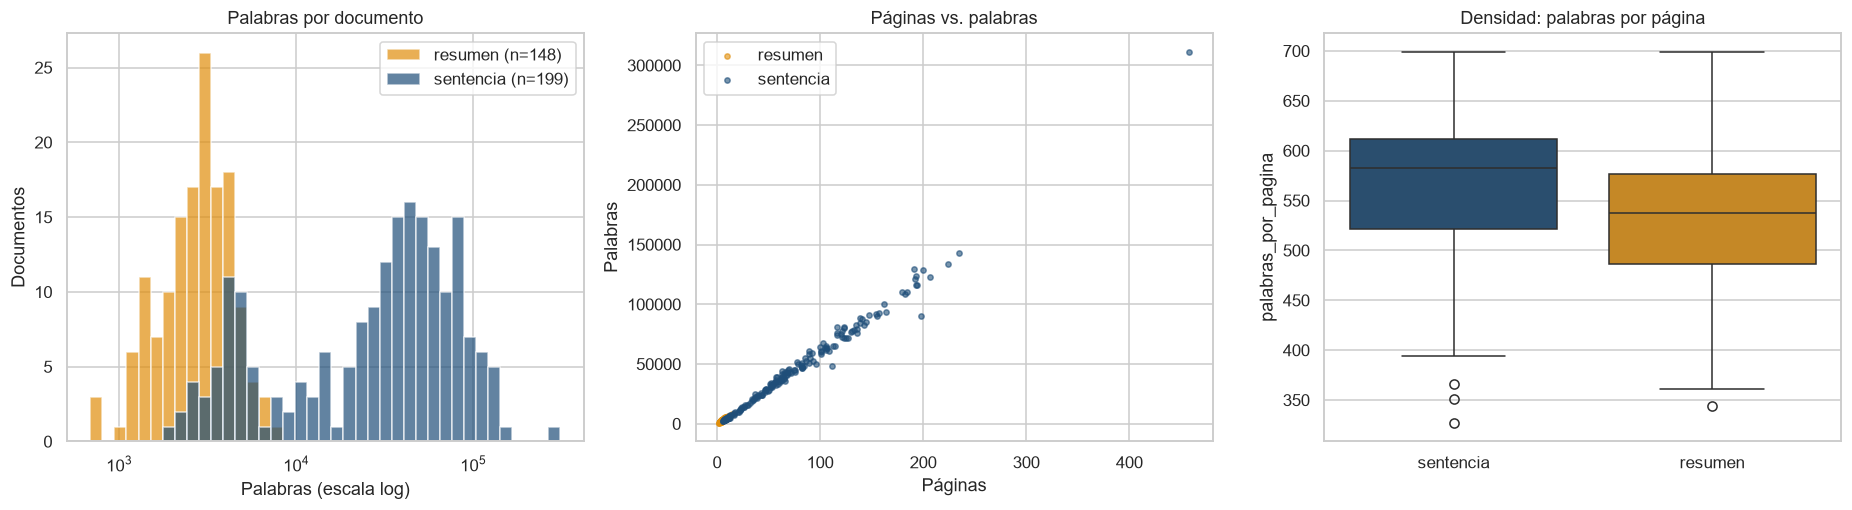

In [22]:
colores = {"sentencia": "#1f4e79", "resumen": "#e08e0b"}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

bins = np.logspace(np.log10(max(df_desc["num_palabras"].min(), 1)), np.log10(df_desc["num_palabras"].max()), 40)
for t, g in df_desc.groupby("tipo_documento"):
    ax[0].hist(g["num_palabras"], bins=bins, alpha=0.7, label=f"{t} (n={len(g)})", color=colores.get(t, "gray"))
ax[0].set_xscale("log"); ax[0].set_xlabel("Palabras (escala log)"); ax[0].set_ylabel("Documentos")
ax[0].set_title("Palabras por documento"); ax[0].legend()

for t, g in df_desc.groupby("tipo_documento"):
    ax[1].scatter(g["num_paginas"], g["num_palabras"], s=12, alpha=0.6, label=t, color=colores.get(t, "gray"))
ax[1].set_xlabel("Páginas"); ax[1].set_ylabel("Palabras"); ax[1].legend()
ax[1].set_title("Páginas vs. palabras")

sns.boxplot(data=df_desc, x="tipo_documento", y="palabras_por_pagina", hue="tipo_documento",
            palette=colores, ax=ax[2], legend=False)
ax[2].set_xlabel(""); ax[2].set_title("Densidad: palabras por página")

guardar_fig("fig01_tamano_documentos")

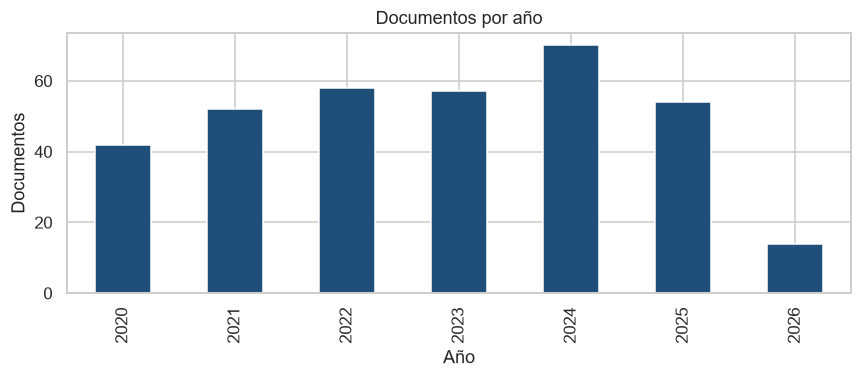

In [23]:
# Distribución temporal (solo tiene sentido con varios años en el corpus)
if "anio" in df and df["anio"].nunique() > 1:
    plt.figure(figsize=(8, 3.6))
    df["anio"].value_counts().sort_index().plot(kind="bar", color="#1f4e79")
    plt.title("Documentos por año"); plt.xlabel("Año"); plt.ylabel("Documentos")
    guardar_fig("fig02_documentos_por_anio")
else:
    print("El corpus de prueba no tiene variación temporal suficiente; se omite la figura.")

terminos mas frecuentes

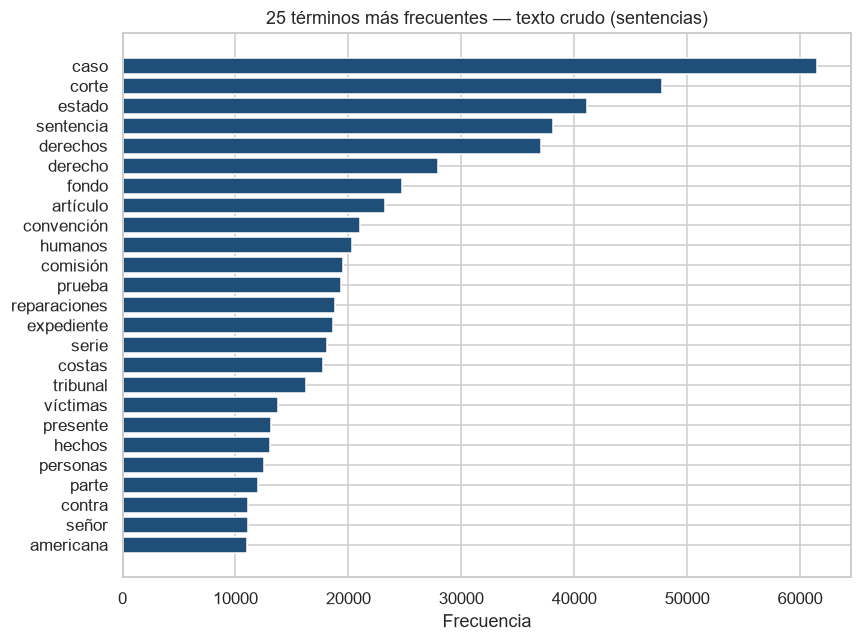

In [24]:
# ── Léxico exploratorio sobre el texto CRUDO (stopwords generales, sin lematizar) ──
# Sirve para ver qué domina el texto antes de preprocesar.
NEGACIONES = {"no", "sin", "ni", "nunca", "tampoco", "contra"}
# spaCy trae "estado" y "parte" como stopwords; en este dominio son términos clave
# (el Estado demandado, las partes del proceso) y NO deben eliminarse.
CONSERVAR = NEGACIONES | {"estado", "parte", "final"}
STOP_BASE = {w for w in STOP_ES if w not in CONSERVAR}
STOP_CITA = {"cfr", "cf", "supra", "infra", "ibíd", "ibid", "ibidem", "ibídem", "op", "cit",
             "párr", "parr", "pág", "págs", "pp", "núm", "vid", "véase"}   # aparato de citas, no contenido

def terminos_utiles(tokens, stop):
    return [t for t in tokens if len(t) > 2 and t not in stop]

df["tokens_crudos"] = df["texto_original"].apply(tokens_simples)
sent_ids = df["en_alcance_rag"]

freq_crudo = Counter()
for toks in df.loc[sent_ids, "tokens_crudos"]:
    freq_crudo.update(terminos_utiles(toks, STOP_BASE | STOP_CITA))

top = pd.DataFrame(freq_crudo.most_common(25), columns=["termino", "frecuencia"])
plt.figure(figsize=(8, 6))
plt.barh(top["termino"][::-1], top["frecuencia"][::-1], color="#1f4e79")
plt.title("25 términos más frecuentes — texto crudo (sentencias)")
plt.xlabel("Frecuencia")
guardar_fig("fig03_top_terminos_crudo")

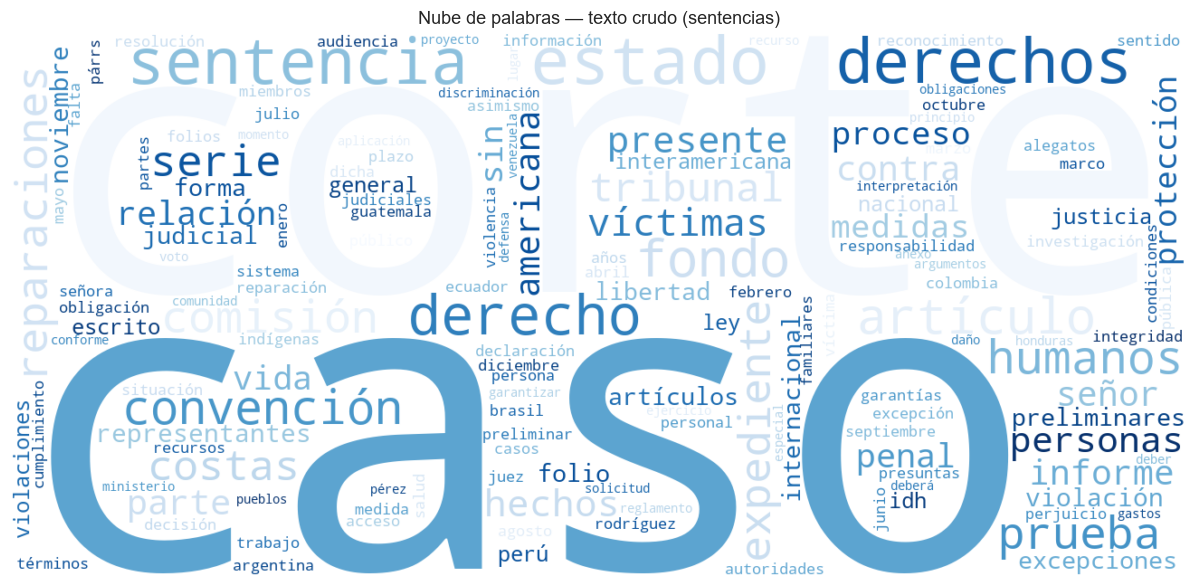

In [25]:
wc = WordCloud(width=1300, height=600, background_color="white", max_words=150,
               colormap="Blues", random_state=42).generate_from_frequencies(freq_crudo)
plt.figure(figsize=(12, 5.5)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
plt.title("Nube de palabras — texto crudo (sentencias)")
guardar_fig("fig04_nube_cruda")

Bigramas frecuentes: revelan expresiones jurídicas compuestas (p. ej. "derechos humanos")

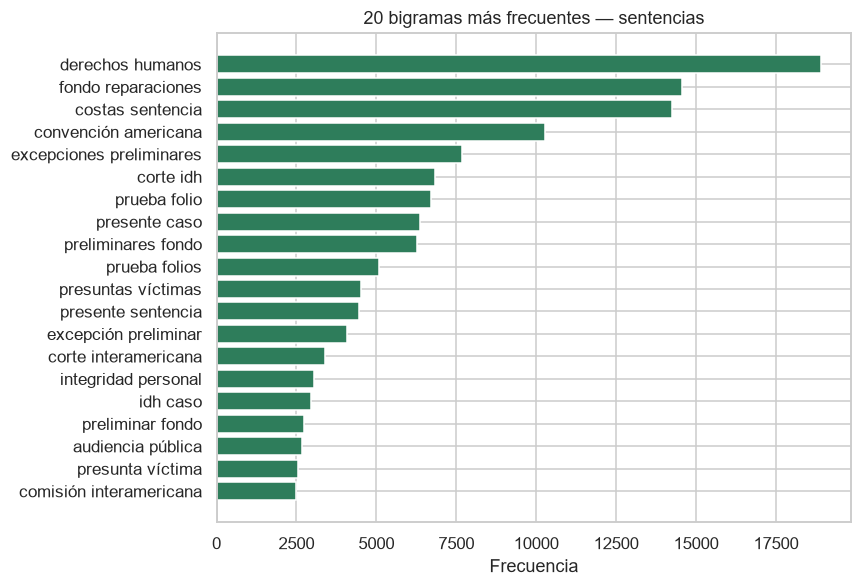

In [26]:
# Bigramas frecuentes: revelan expresiones jurídicas compuestas (p. ej. "derechos humanos")
stop_bi = STOP_BASE | STOP_CITA
bigramas = Counter()
for toks in df.loc[sent_ids, "tokens_crudos"]:
    for a, b in zip(toks, toks[1:]):
        if len(a) > 2 and len(b) > 2 and a not in stop_bi and b not in stop_bi:
            bigramas[(a, b)] += 1

top_bi = pd.DataFrame([(" ".join(k), v) for k, v in bigramas.most_common(20)],
                      columns=["bigrama", "frecuencia"])
plt.figure(figsize=(8, 5.5))
plt.barh(top_bi["bigrama"][::-1], top_bi["frecuencia"][::-1], color="#2e7d5b")
plt.title("20 bigramas más frecuentes — sentencias"); plt.xlabel("Frecuencia")
guardar_fig("fig05_bigramas")

Ley de Zipf: en un corpus natural, la frecuencia de una palabra es aproximadamente inversamente proporcional a su rango. Una recta en escala log-log confirma que el texto extraído se comporta como lenguaje natural (y no como ruido de extracción).

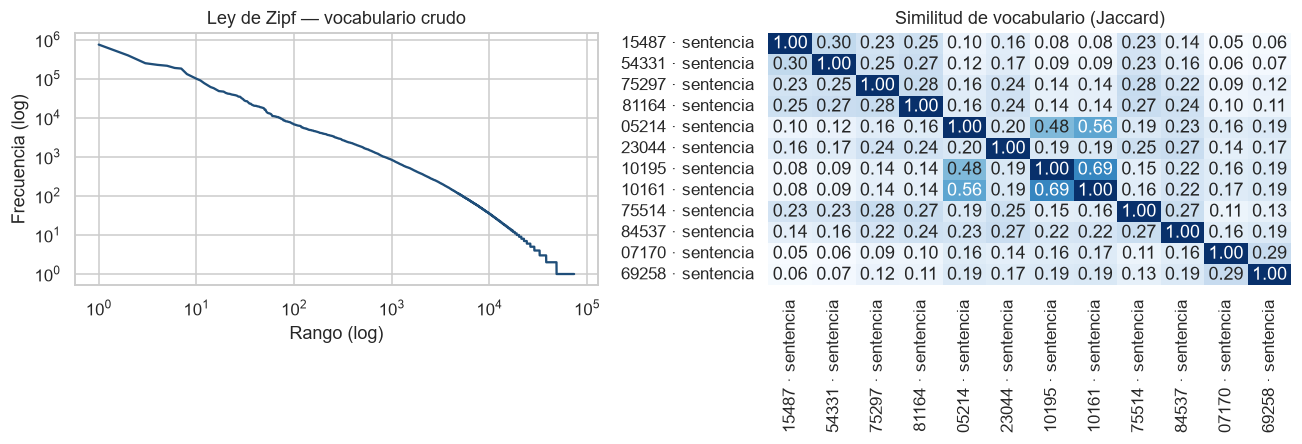

In [27]:
# Ley de Zipf: la frecuencia cae de forma potencial con el rango

freq_all = Counter()

for toks in df.loc[sent_ids, "tokens_crudos"]:
    freq_all.update(toks)
valores = np.array(sorted(freq_all.values(), reverse=True))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].loglog(np.arange(1, len(valores) + 1), valores, color="#1f4e79")
ax[0].set_xlabel("Rango (log)"); ax[0].set_ylabel("Frecuencia (log)"); ax[0].set_title("Ley de Zipf — vocabulario crudo")

# Similitud de vocabulario entre documentos
muestra = df[sent_ids].sample(min(12, int(sent_ids.sum())), random_state=42)
vocabs = {r.etiqueta: {t for t in r.tokens_crudos if len(t) > 3 and t not in STOP_BASE} for r in muestra.itertuples()}
et = list(vocabs)
J = pd.DataFrame([[len(vocabs[a] & vocabs[b]) / len(vocabs[a] | vocabs[b]) for b in et] for a in et],
                 index=et, columns=et)
sns.heatmap(J, annot=True, fmt=".2f", cmap="Blues", ax=ax[1], cbar=False)
ax[1].set_title("Similitud de vocabulario (Jaccard)")
guardar_fig("fig06_zipf_y_jaccard")

**Pipeline secuencial**
***

In [28]:
# @title
CONFIG = {
    "umbral_lineas_repetidas": 0.40,   # fracción de páginas en que debe repetirse una línea
    "ventana_numeracion": 5,           # tolerancia a saltos en la numeración de párrafos
    "modelo_spacy": "es_core_news_sm",
    "min_len_token": 3,
    "parrafo_min_palabras": 5,         # por debajo se marca como párrafo corto
    "max_palabras_no_numerado": 200,   # bloques sin numeración (p. ej. el resumen) se parten por oraciones
}

LIGADURAS = {"\ufb00": "ff", "\ufb01": "fi", "\ufb02": "fl", "\ufb03": "ffi", "\ufb04": "ffl"}

# ── NUEVO: títulos de sección y marcadores de nota al pie ──
RE_TITULO = re.compile(r"^[IVX]{1,6}(?:-\d{1,2})?\.\s+(?!.*\.{4,})[A-ZÁÉÍÓÚÑÜ][A-ZÁÉÍÓÚÑÜ0-9 ,;:()/.\-–\"']{3,}$")
RE_ROMANO_SOLO      = re.compile(r"[IVX]{1,6}(?:-\d{1,2})?\.?")
RE_MARCA_PEGADA     = re.compile(r"\b([^\W\d_]{3,})\d{1,4}\b")                  # misma1, Juristas2, palabra1034
RE_MARCA_TRAS_PUNTO = re.compile(r"(?<=[^\W\d_][.,;:)])\d{1,4}(?=[\s,;:]|$)")   # Corte.15  EXPRESIÓN)77,  (no "A.1.")
# Las sentencias más largas superan los 999 párrafos
RE_NUM_PARR = re.compile(r"^(\d{1,4})\.\s+(?=\S)")
RE_NUM_SOLO = re.compile(r"^(\d{1,4})\.$")
# Puntos resolutivos y votos individuales: reinician la numeración en 1 y no deben pegarse al último párrafo
RE_RESOLUTIVOS = re.compile(r"(?:[IVX]{1,6}(?:-\d{1,2})?\.?\s+)?PUNTOS RESOLUTIVOS[.:]?")
# Bloque de firmas al final de la sentencia: nombres de jueces, no contenido
# algunas no traen "Redactada en": la firma empieza con la referencia "Corte IDH. Caso ... Sentencia de ..."
RE_FIRMAS = re.compile(r"^(?:(?:Redactada|Hecha|Dada) en (?:español|inglés|portugués|francés)\b|Corte IDH\. Caso\b)")
RE_VOTO = re.compile(r"^VOTO\s+(?:PARCIALMENTE\s+)?(?:CONCURRENTE|RAZONADO|DISIDENTE|CONJUNTO|INDIVIDUAL|SEPARADO|SALVADO)\b")

def nueva_parte(linea, parte):
    if RE_VOTO.match(linea) and linea.isupper():
        return "voto"
    if parte == "cuerpo" and RE_RESOLUTIVOS.match(linea) and linea.isupper():   # p. ej. "... LA CORTE DECLARA,"
        return "resolutivos"
    if parte == "resolutivos" and RE_FIRMAS.match(linea):           # en el cuerpo y los votos esas líneas pueden ser citas
        return "firmas"
    return None


def marcar_portada(df_parr):
    """Portada e índice: todo lo anterior al párrafo 1 del cuerpo (el índice también trae títulos de sección)."""
    p1 = df_parr[df_parr["parte"].eq("cuerpo") & df_parr["num_parrafo"].eq(1).fillna(False)].groupby("doc_id")["orden"].min()
    inicio = df_parr["doc_id"].map(p1)
    sin_p1 = inicio.isna() & df_parr["seccion"].eq("ENCABEZADO")      # sin numeración detectada: criterio anterior
    return df_parr["doc_id"].str.endswith("_sentencia") & (df_parr["orden"].lt(inicio) | sin_p1)

# ──────────────────────────── Etapa 1 ────────────────────────────
def normalizar_unicode(t):
    t = unicodedata.normalize("NFC", t)

    for k, v in LIGADURAS.items():
        t = t.replace(k, v)

    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = re.sub(r"[\u00ad\u200b\u200c\u200d\ufeff]", "", t)          # guion blando, espacios de ancho cero
    t = t.replace("\xa0", " ")
    t = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]", " ", t)          # caracteres de control
    t = re.sub(r"[“”«»„]", '"', t)
    t = re.sub(r"[‘’]", "'", t)

    return t

# NUEVO: quita los números de nota al pie pegados a una palabra o a la puntuación
def quitar_marcas_nota(t):
    t, n1 = RE_MARCA_PEGADA.subn(r"\1", t)
    t, n2 = RE_MARCA_TRAS_PUNTO.subn("", t)
    return t, n1 + n2

# NUEVO: "I." + "INTRODUCCIÓN DE LA CAUSA..." (en líneas separadas) -> "I. INTRODUCCIÓN DE LA CAUSA..."
def _es_linea_titulo(l):
    return l.isupper() and not l.startswith("CASO ")

def unir_titulos(t):
    lineas, unidas, i, n = t.split("\n"), [], 0, 0
    while i < len(lineas):
        l = lineas[i]
        if RE_ROMANO_SOLO.fullmatch(l) and i + 1 < len(lineas) and _es_linea_titulo(lineas[i + 1]):
            j, titulo = i + 1, []
            while j < len(lineas) and _es_linea_titulo(lineas[j]) and len(titulo) < 3:
                titulo.append(lineas[j]); j += 1
            unidas.append(l.rstrip(".") + ". " + " ".join(titulo)); n += 1
            i = j
        else:
            unidas.append(l); i += 1
    return "\n".join(unidas), n

# Parte un bloque largo sin numeración en trozos de <= max_pal palabras
def dividir_bloque_largo(p, max_pal):

    if len(p.split()) <= max_pal:
        return [p]

    trozos, actual, n = [], [], 0

    for oracion in re.split(r"(?<=[.!?])\s+", p):
        k = len(oracion.split())
        if actual and n + k > max_pal:
            trozos.append(" ".join(actual)); actual, n = [], 0
        actual.append(oracion); n += k

    if actual:
        trozos.append(" ".join(actual))

    return trozos

# ──────────────────────────── Etapas 2-4 ────────────────────────────
def limpiar_texto(texto, n_paginas, cfg=CONFIG):
    stats = Counter()
    t = normalizar_unicode(texto)

    # NUEVO: marcadores de nota al pie pegados a palabras
    t, n = quitar_marcas_nota(t)
    stats["marcas_nota_quitadas"] = n

    # Etapa 2: encabezados / pie de pagina/ numeros de pagina
    repetidas = detectar_lineas_repetidas(t, n_paginas, cfg["umbral_lineas_repetidas"])
    lineas = []

    for l in t.split("\n"):
        l = l.strip()
        if not l:
            continue

        if l in repetidas:
            stats["lineas_encabezado_pie"] += 1; continue

        if RE_PAGINA.match(l):
            stats["lineas_num_pagina"] += 1; continue

        lineas.append(l)

    t = "\n".join(lineas)

    # Etapa 3: palabras cortadas por guion al final de línea
    t, n = RE_GUION_CORTE.subn("", t)
    stats["palabras_unidas_guion"] = n

    # NUEVO, Etapa 3b: unir numeral romano suelto con su título
    t, n = unir_titulos(t)
    stats["titulos_unidos"] = n

    # Etapa 4: reconstrucción de párrafos, separando cuerpo, puntos resolutivos y votos
    parrafos, actual = [], []
    parte = parte_parr = "cuerpo"           # parte del documento y del párrafo abierto
    ultimo, ultimo_cuerpo = 0, 0

    def cerrar():
        if actual:
            parrafos.append((parte_parr, False, " ".join(actual))); actual.clear()

    for l in t.split("\n"):
        # solo después del primer párrafo numerado: el índice de la portada también lista "PUNTOS RESOLUTIVOS"
        nueva = nueva_parte(l, parte) if (ultimo or parte != "cuerpo") else None
        if nueva:
            cerrar()
            if parte == "cuerpo":
                ultimo_cuerpo = ultimo
            parte = parte_parr = nueva; ultimo = 0          # resolutivos y votos reinician la numeración
            stats[f"inicio_{parte}"] += 1

        if nueva in ("resolutivos", "voto") or RE_TITULO.match(l):     # la línea de firmas es texto, no título
            cerrar(); parrafos.append((parte, True, l))
            if nueva != "voto":
                stats["titulos"] += 1
            continue

        m = RE_NUM_PARR.match(l) or RE_NUM_SOLO.match(l)

        if m:
            n_p, w = int(m.group(1)), cfg["ventana_numeracion"]
            if ultimo < n_p <= ultimo + w:                    # la numeración debe ser consecutiva
                cerrar(); ultimo = n_p; parte_parr = parte; stats["parrafos_numerados"] += 1
            elif parte == "resolutivos" and ultimo == 0 and ultimo_cuerpo < n_p <= ultimo_cuerpo + w:
                # "189. Por tanto," continúa la numeración del cuerpo antes del punto resolutivo 1
                cerrar(); ultimo_cuerpo = n_p; parte_parr = "cuerpo"; stats["parrafos_numerados"] += 1

        actual.append(l)
    cerrar()

    finales = []
    for pa, es_titulo, p in parrafos:
        p = re.sub(r"\s+", " ", p).strip()
        if es_titulo or RE_NUM_PARR.match(p):
            finales.append((pa, es_titulo, p))          # títulos y párrafos numerados se respetan tal cual
        else:
            finales.extend((pa, False, x) for x in dividir_bloque_largo(p, cfg["max_palabras_no_numerado"]))

    texto_limpio = "\n\n".join(p for _, _, p in finales)
    stats["parrafos_totales"] = len(finales)

    return texto_limpio, dict(stats), finales

# ──────────────────────────── Etapa 5 ────────────────────────────
def segmentar_parrafos(doc_id, bloques, cfg=CONFIG):
    filas, seccion, orden = [], "ENCABEZADO", 0

    for parte, es_titulo, p in bloques:
        if es_titulo:
            seccion = p; continue

        m = RE_NUM_PARR.match(p)
        num = int(m.group(1)) if m else None
        cuerpo = RE_NUM_PARR.sub("", p, count=1) if m else p
        orden += 1
        nw = len(cuerpo.split())

        filas.append({"doc_id": doc_id, "orden": orden, "parte": parte, "seccion": seccion, "num_parrafo": num,
                      "texto": cuerpo, "num_palabras": nw, "es_corto": nw < cfg["parrafo_min_palabras"]})
    return filas

In [29]:
# Aplicacion de las etapas 1-5 al corpus
limpios, stats_lista, parr_filas = [], [], []

for r in tqdm(df.itertuples(), total=len(df), desc="Limpieza"):
    txt, st, bloques = limpiar_texto(r.texto_cuerpo, r.numero_paginas)
    limpios.append(txt)
    stats_lista.append({"doc_id": r.doc_id, **st})
    parr_filas.extend(segmentar_parrafos(r.doc_id, bloques))

df["texto_limpio"] = limpios
df_stats = pd.DataFrame(stats_lista).fillna(0).set_index("doc_id").astype(int)
df_parr = pd.DataFrame(parr_filas)
df_parr["num_parrafo"] = df_parr["num_parrafo"].astype("Int64")

# NUEVO: portada + índice de las sentencias (los resúmenes no tienen secciones, no se marcan)
df_parr["es_portada"] = marcar_portada(df_parr)

print(f"Párrafos generados: {len(df_parr):,}")
display(df_stats)

Párrafos generados: 56,132


,marcas_nota_quitadas,lineas_num_pagina,palabras_unidas_guion,titulos_unidos,titulos,parrafos_numerados,inicio_resolutivos,inicio_firmas,parrafos_totales,inicio_voto,lineas_encabezado_pie
doc_id,,,,,,,,,,,
1025868111_sentencia,2,36,0,5,5,160,1,1,169,0,0
1031550500_sentencia,0,17,0,5,5,60,1,1,69,0,0
1034838366_sentencia,0,1,0,12,12,209,1,1,232,0,0
1034838366_resumen,0,7,0,0,0,0,0,0,21,0,0
1035032346_sentencia,0,21,0,11,11,73,1,1,90,0,0
...,...,...,...,...,...,...,...,...,...,...,...
980571262_resumen,2,7,0,0,0,0,0,0,22,0,0
980571899_sentencia,4,208,5,13,18,676,1,1,715,2,0
980571899_resumen,0,6,0,0,0,0,0,0,25,0,0


In [30]:
val = []
# solo el cuerpo: puntos resolutivos y votos tienen su propia numeración
for doc_id, g in df_parr[df_parr["parte"].eq("cuerpo")].groupby("doc_id"):
    nums = g["num_parrafo"].dropna().astype(int)
    if nums.empty:
        val.append({"doc_id": doc_id, "numerados": 0, "max_num": None, "faltantes": None, "cobertura_%": None})
        continue
    esperados = set(range(1, nums.max() + 1))
    faltan = sorted(esperados - set(nums))
    val.append({"doc_id": doc_id, "numerados": len(nums), "max_num": int(nums.max()),
                "faltantes": len(faltan), "cobertura_%": round(100 * (1 - len(faltan) / nums.max()), 1),
                "primeros_faltantes": faltan[:8]})
display(pd.DataFrame(val))
print("Nota: el resumen no tiene párrafos numerados; es esperado que salga vacío.")

,doc_id,numerados,max_num,faltantes,cobertura_%,primeros_faltantes
0,1025868111_sentencia,150,150.0,0.0,100.0,[]
1,1031550500_sentencia,56,56.0,0.0,100.0,[]
2,1034838366_resumen,0,NaN,NaN,NaN,NaN
3,1034838366_sentencia,188,188.0,0.0,100.0,[]
4,1035032346_resumen,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
342,980571262_sentencia,247,247.0,0.0,100.0,[]
343,980571899_resumen,0,NaN,NaN,NaN,NaN
344,980571899_sentencia,393,393.0,0.0,100.0,[]
345,980572019_resumen,0,NaN,NaN,NaN,NaN


Nota: el resumen no tiene párrafos numerados; es esperado que salga vacío.


In [31]:
# Ejemplo antes → después sobre un fragmento real
r = df[df["doc_id"] == doc_ref["doc_id"]].iloc[0]
# un párrafo real del cuerpo (fuera de portada e índice) y su ubicación en el texto crudo
p_ej = df_parr[(df_parr["doc_id"] == r["doc_id"]) & ~df_parr["es_portada"] & df_parr["parte"].eq("cuerpo")
               & df_parr["num_palabras"].between(40, 120)].iloc[0]
m = re.search(r"\s+".join(map(re.escape, p_ej["texto"].split()[:4])), r["texto_original"])
ini = m.start() if m else r["texto_original"].find("\n", 3000)

print(" ────────────────────────────── TEXTO CRUDO (extracción PDF) ──────────────────────────────")
print(r["texto_original"][ini:ini + 700])

print("\n ────────────────────────────── TEXTO LIMPIO (párrafos reconstruidos)  ──────────────────────────────")
print(f"[sección: {p_ej['seccion']} | párrafo nº {p_ej['num_parrafo']}]")
print(p_ej["texto"])

 ────────────────────────────── TEXTO CRUDO (extracción PDF) ──────────────────────────────
Notificación al Estado. - El Informe de Fondo fue notificado al Estado mediante 
comunicación de 8 de octubre de 2019, habiéndosele otorgado el plazo de dos meses para 
que informara sobre el cumplimiento de las recomendaciones formuladas. La Comisión, 
después de otorgar dos prórrogas al Estado, negó el otorgamiento de una nueva prórroga, 
debido a que Colombia “no [había] present[ado] información sustantiva que revelara avances 
relevantes en el cumplimiento de las recomendaciones”. 
 
4. 
Sometimiento a la Corte. - El 8 de julio de 2020 la Comisión sometió a la Corte la 
totalidad de los hechos y violaciones a derechos humanos del caso. Lo hizo, según indicó, “por 
la necesidad de obtenci

 ────────────────────────────── TEXTO LIMPIO (párrafos reconstruidos)  ──────────────────────────────
[sección: I. INTRODUCCIÓN DE LA CAUSA Y OBJETO DE LA CONTROVERSIA | párrafo nº 3]
Notificación al Estado

In [32]:
# ──────────────────────────── Etapas 6-7: tokenización, lematización y filtrado ────────────────────────────
nlp = spacy.load(CONFIG["modelo_spacy"], disable=["parser", "ner"])   # Lematizador y morfologizador
nlp.max_length = 2_000_000

STOPWORDS = STOP_BASE | STOP_CITA
POS_FUNCION = {"PRON", "DET", "ADP", "CCONJ", "SCONJ", "AUX"}     # pronombres como "él" se colaban como lemas

# "artículo 8.1" -> "art_8_1": los números de artículo son términos clave y el filtro alfabético los borraba
# shortcut: no distingue la Convención del Reglamento u otros tratados; añadir el instrumento si hace falta
RE_ARTICULOS = re.compile(r"\b(?:art[íi]culos?|arts?\.)\s+(\d{1,3}(?:\.\d{1,2})?(?:\s*(?:,|y|e)\s*\d{1,3}(?:\.\d{1,2})?)*)", re.I)
RE_ART_TOKEN = re.compile(r"art_\d{1,3}(?:_\d{1,2})?")

def marcar_articulos(texto):
    return RE_ARTICULOS.sub(lambda m: " ".join("art_" + n.replace(".", "_")
                                               for n in re.findall(r"\d{1,3}(?:\.\d{1,2})?", m.group(1))), texto)

def filtrar_tokens(doc):
    out = []
    for tok in doc:
        txt = tok.text.lower()
        if RE_ART_TOKEN.fullmatch(txt):
            out.append(txt); continue
        if not tok.is_alpha:
            continue

        lem = tok.lemma_.lower()
        if lem in CONSERVAR:                 # negaciones y términos del dominio, aunque sean cortos o stopwords
            out.append(lem); continue

        if tok.pos_ in POS_FUNCION or len(lem) < CONFIG["min_len_token"] or lem in STOPWORDS or txt in STOPWORDS:
            continue
        out.append(lem)
    return out

# Una sola normalización para párrafos, chunks y consultas
def normalizar_lote(textos, desc="Lematización"):
    docs = nlp.pipe((marcar_articulos(t) for t in textos), batch_size=64)
    return [filtrar_tokens(d) for d in tqdm(docs, total=len(textos), desc=desc)]

def normalizar(texto):
    return " ".join(filtrar_tokens(nlp(marcar_articulos(texto))))

# Se procesa por párrafo (unidad corta => rápido y sin problemas de memoria)
lemas = normalizar_lote(df_parr["texto"])

df_parr["lemas"] = lemas
df_parr["texto_normalizado"] = df_parr["lemas"].apply(" ".join)
df_parr["num_lemas"] = df_parr["lemas"].apply(len)

norm_doc = df_parr.groupby("doc_id")["texto_normalizado"].apply(" ".join)
df["texto_normalizado"] = df["doc_id"].map(norm_doc).fillna("")
df_parr[["doc_id", "seccion", "num_parrafo", "num_palabras", "num_lemas", "texto_normalizado"]].head(5)

,doc_id,seccion,num_parrafo,num_palabras,num_lemas,texto_normalizado
0,1025868111_sentencia,ENCABEZADO,<NA>,99,63,corte interamericana derechos humanos caso integrante militante unión patriótico colom...
1,1025868111_sentencia,ENCABEZADO,<NA>,199,85,sijniensky secretaria adjunta conformidad art_67 convención americana derechos humanos...
2,1025868111_sentencia,ENCABEZADO,<NA>,173,54,familiar víctima encontrar listada anexo sentencia argumento parte comisión considerac...
3,1025868111_sentencia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,1,72,26,julio corte interamericana emitir sentencia presente caso sentencia notificar parte co...
4,1025868111_sentencia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,2,57,23,marzo intervinient común derechos dignidad presentar solicitud interpretación relación...


In [33]:
# @title
# Trazabilidad de una misma frase a lo largo del pipeline
frase = p_ej["texto"].split(". ")[0][:400]
doc = nlp(frase)
print("1) LIMPIO      :", frase)
print("\n2) TOKENS      :", [t.text for t in doc][:25], "...")
print("\n3) LEMAS       :", [t.lemma_ for t in doc][:25], "...")
print("\n4) FILTRADO    :", filtrar_tokens(doc))

1) LIMPIO      : Notificación al Estado

2) TOKENS      : ['Notificación', 'al', 'Estado'] ...

3) LEMAS       : ['Notificación', 'al', 'Estado'] ...

4) FILTRADO    : ['notificación', 'estado']


,palabras_original,palabras_limpio,tokens_normalizados,vocab_crudo,vocab_normalizado,reduccion_texto_%,reduccion_tokens_%,reduccion_vocab_%
doc_id,,,,,,,,
1025868111_sentencia,22598,19439,8254,2390,1300,14.0,63.5,45.6
1031550500_sentencia,9544,7272,3143,1409,767,23.8,67.1,45.6
1034838366_sentencia,33208,22589,10357,3381,1901,32.0,68.8,43.8
1034838366_resumen,3745,3705,1782,818,584,1.1,52.4,28.6
1035032346_sentencia,11281,8019,3370,1762,902,28.9,70.1,48.8
1035032346_resumen,725,723,320,271,175,0.3,55.9,35.4
1039244171_sentencia,65252,45435,19707,6084,3338,30.4,69.8,45.1
1039244171_resumen,3313,3206,1399,881,605,3.2,57.8,31.3
1039351190_sentencia,43270,30705,13476,3916,1993,29.0,68.9,49.1


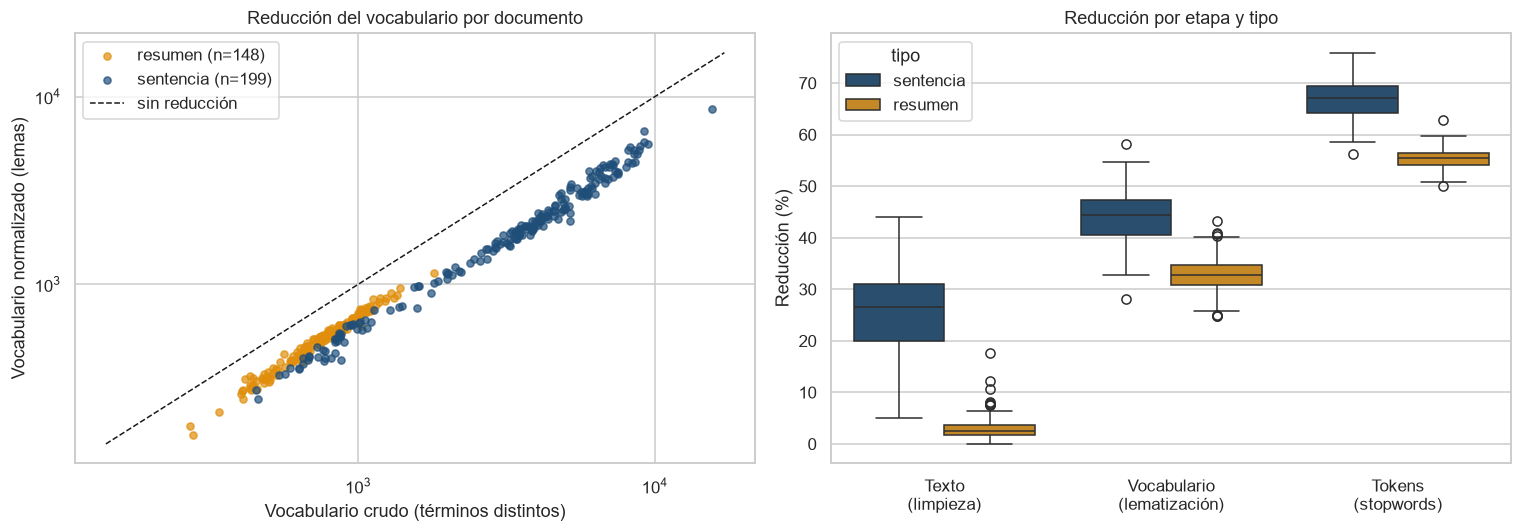

In [34]:
# ── Tabla de comparación antes / después del preprocesamiento ──
comp = []

for r in df.itertuples():
    tok_crudo = r.tokens_crudos
    lem = r.texto_normalizado.split()
    comp.append({
        "doc_id": r.doc_id,
        "palabras_original": r.numero_palabras,
        "palabras_limpio": len(r.texto_limpio.split()),
        "tokens_normalizados": len(lem),
        "vocab_crudo": len(set(tok_crudo)),
        "vocab_normalizado": len(set(lem)),
    })

df_comp = pd.DataFrame(comp).set_index("doc_id")
df_comp["reduccion_texto_%"] = (100 * (1 - df_comp["palabras_limpio"] / df_comp["palabras_original"])).round(1)
df_comp["reduccion_tokens_%"] = (100 * (1 - df_comp["tokens_normalizados"] / df_comp["palabras_original"])).round(1)
df_comp["reduccion_vocab_%"] = (100 * (1 - df_comp["vocab_normalizado"] / df_comp["vocab_crudo"])).round(1)
df_comp["tipo"] = df_comp.index.str.rsplit("_", n=1).str[-1]
display(df_comp.drop(columns="tipo").head(10))

# ── Gráfico ──
colores = {"sentencia": "#1f4e79", "resumen": "#e08e0b"}

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for t, g in df_comp.groupby("tipo"):
    ax[0].scatter(g["vocab_crudo"], g["vocab_normalizado"], s=22, alpha=0.7,
                  color=colores.get(t, "gray"), label=f"{t} (n={len(g)})")
lim = [df_comp["vocab_normalizado"].min() * 0.9, df_comp["vocab_crudo"].max() * 1.1]
ax[0].plot(lim, lim, "k--", lw=1, label="sin reducción")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Vocabulario crudo (términos distintos)")
ax[0].set_ylabel("Vocabulario normalizado (lemas)")
ax[0].set_title("Reducción del vocabulario por documento"); ax[0].legend()

nombres = {"reduccion_texto_%": "Texto\n(limpieza)",
           "reduccion_vocab_%": "Vocabulario\n(lematización)",
           "reduccion_tokens_%": "Tokens\n(stopwords)"}
largo = (df_comp.melt(id_vars="tipo", value_vars=list(nombres), var_name="etapa", value_name="reduccion")
                .assign(etapa=lambda d: d["etapa"].map(nombres)))
sns.boxplot(data=largo, x="etapa", y="reduccion", hue="tipo", palette=colores, ax=ax[1])
ax[1].set_xlabel(""); ax[1].set_ylabel("Reducción (%)"); ax[1].set_title("Reducción por etapa y tipo")

guardar_fig("fig07_vocabulario_antes_despues")

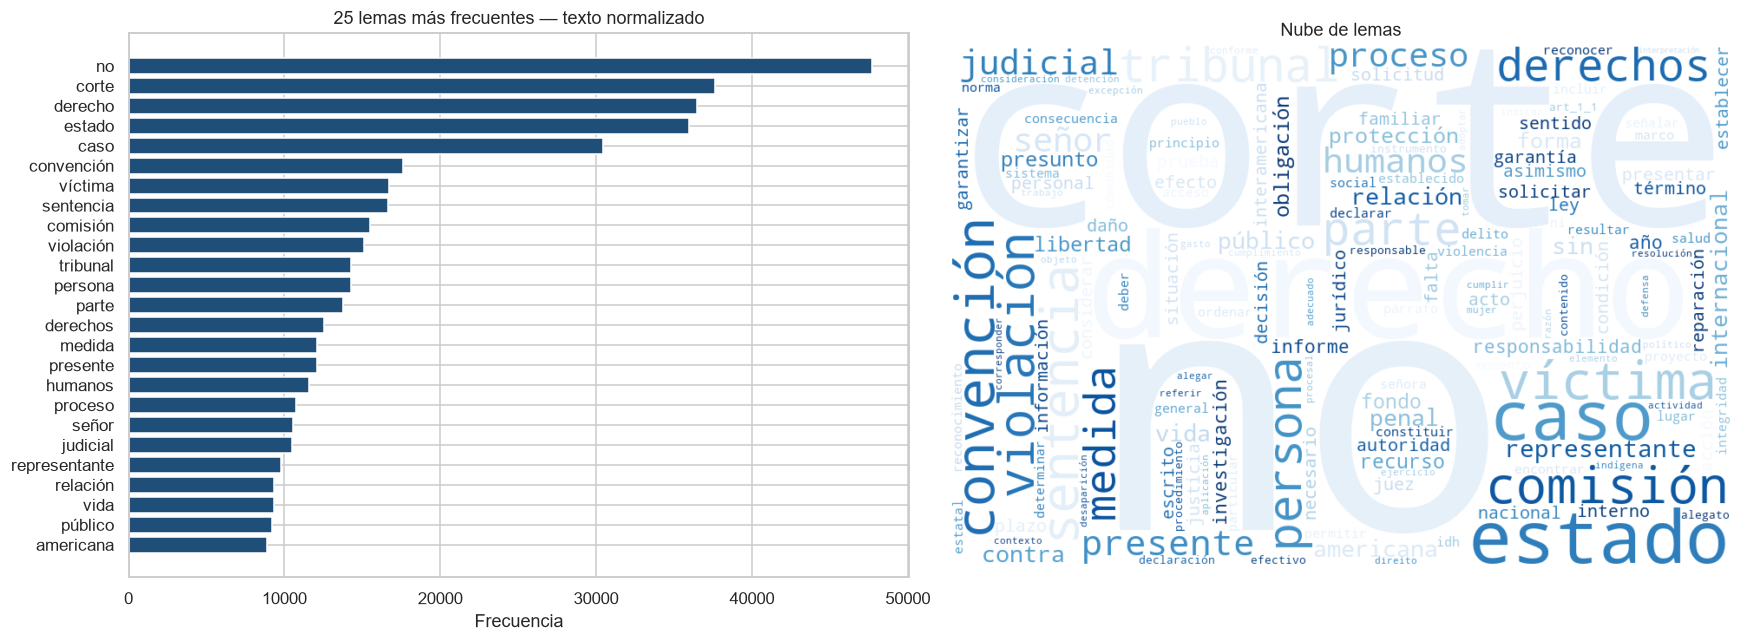

Lemas presentes en todas las sentencias (candidatos a revisar, NO eliminados):
 ['no', 'corte', 'derecho', 'estado', 'caso', 'convención', 'sentencia', 'comisión', 'tribunal', 'parte', 'derechos', 'medida', 'presente', 'humanos', 'americana', 'fondo', 'presentar', 'solicitar', 'solicitud', 'asimismo', 'interamericana', 'plazo', 'párrafo', 'declarar', 'establecido', 'determinar', 'corresponder', 'presentado', 'reglamento', 'conformidad']


Sentencias sin el lema «corte»: 0 []
Sentencias sin el lema «caso»: 0 []
Sentencias sin el lema «estado»: 0 []
Sentencias sin el lema «convención»: 0 []
Sentencias sin el lema «sentencia»: 0 []


In [35]:
# Términos y nube despues del preprocesamiento (lemas)
freq_lem = Counter()

for lem in df_parr.loc[df_parr["doc_id"].isin(df.loc[sent_ids, "doc_id"]), "lemas"]:
    freq_lem.update(lem)

top_l = pd.DataFrame(freq_lem.most_common(25), columns=["lema", "frecuencia"])
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].barh(top_l["lema"][::-1], top_l["frecuencia"][::-1], color="#1f4e79")
ax[0].set_title("25 lemas más frecuentes — texto normalizado"); ax[0].set_xlabel("Frecuencia")
wc = WordCloud(width=900, height=600, background_color="white", max_words=150,
               colormap="Blues", random_state=42).generate_from_frequencies(freq_lem)
ax[1].imshow(wc, interpolation="bilinear"); ax[1].axis("off"); ax[1].set_title("Nube de lemas")
guardar_fig("fig08_lemas_despues")

# Candidatos a stopwords de dominio: lemas presentes en TODOS los documentos en alcance
df_en_alcance = df[sent_ids]
if len(df_en_alcance) > 1:
    presencia = Counter()
    for t in df_en_alcance["texto_normalizado"]:
        presencia.update(set(t.split()))

    ubicuos = sorted([w for w, c in presencia.items() if c == len(df_en_alcance)],
                     key=lambda w: -freq_lem[w])[:30]

    print("Lemas presentes en todas las sentencias (candidatos a revisar, NO eliminados):\n", ubicuos)

    # Términos que deberían aparecer en todas las sentencias: si faltan, revisar lematización o extracción
    conjuntos = [set(t.split()) for t in df_en_alcance["texto_normalizado"]]
    for w in ("corte", "caso", "estado", "convención", "sentencia"):
        faltan = [d for d, c in zip(df_en_alcance["doc_id"], conjuntos) if w not in c]
        print(f"Sentencias sin el lema «{w}»: {len(faltan)}", faltan[:5])

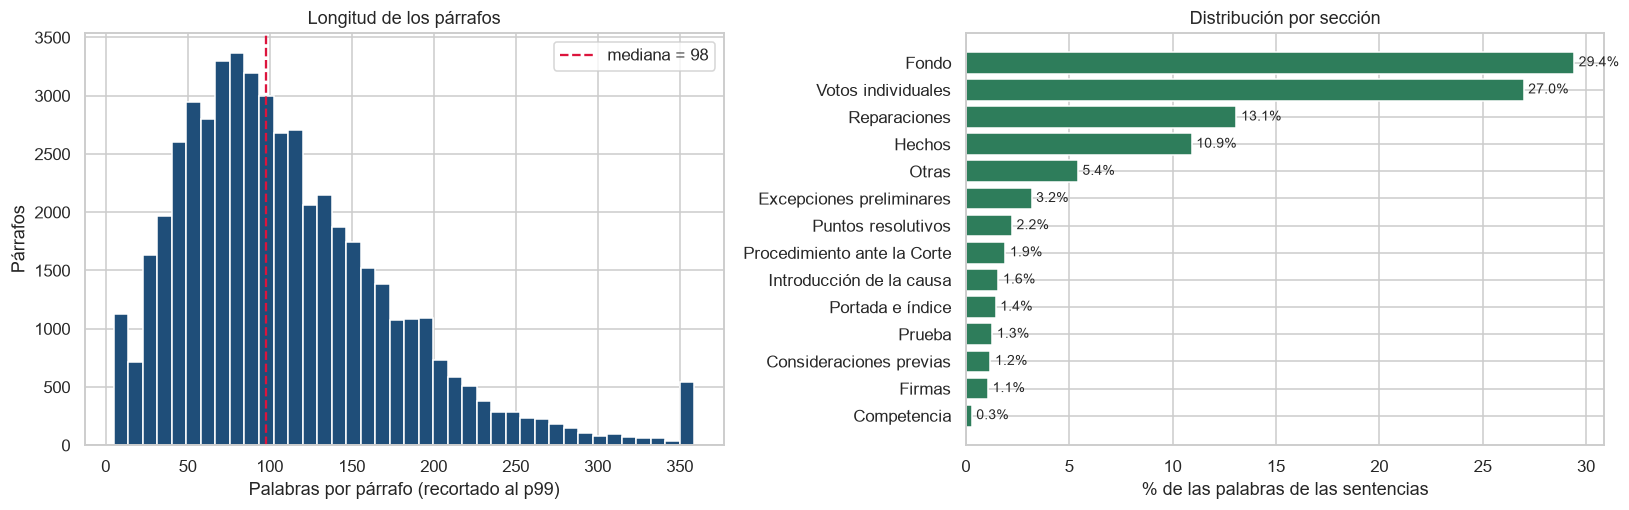

Cuantiles de longitud de párrafo (palabras):


,0.05,0.25,0.50,0.75,0.90,0.95,0.99
palabras,27.0,63.0,98.0,146.0,196.0,233.0,359.0


Párrafos > 300 palabras: 916 de 50644


In [36]:
# Párrafos de las sentencias (sin los muy cortos), base para el histograma y las secciones
pa = df_parr[df_parr["doc_id"].isin(df.loc[sent_ids, "doc_id"]) & ~df_parr["es_corto"]].copy()

def canon_seccion(s):
    if s == "ENCABEZADO":
        return "Portada e índice"
    t = re.sub(r"\s+", " ", re.sub(r"^[IVX]+(?:-\d+)?\.?\s+", "", s)).upper()
    reglas = [("Introducción de la causa", "INTRODUCCI"), ("Procedimiento ante la Corte", "PROCEDIMIENTO"),
              ("Competencia", "COMPETENCIA"), ("Excepciones preliminares", "EXCEPCI"),
              ("Consideraciones previas", "CONSIDERACIONES PREVIAS"), ("Prueba", "PRUEBA"),
              ("Hechos", "HECHOS"), ("Fondo", "FONDO|DERECHO"),
              ("Reparaciones", "REPARACI"), ("Puntos resolutivos", "PUNTOS RESOLUTIVOS")]
    for nombre, patron in reglas:
        if re.search(patron, t):
            return nombre
    return "Otras"

def seccion_canonica(d):
    return d["parte"].map({"voto": "Votos individuales", "firmas": "Firmas"}).fillna(d["seccion"].map(canon_seccion))

pa["sec"] = seccion_canonica(pa)
por_sec = pa.groupby("sec")["num_palabras"].sum().sort_values()
por_sec = 100 * por_sec / por_sec.sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].hist(pa["num_palabras"].clip(upper=pa["num_palabras"].quantile(0.99)), bins=40, color="#1f4e79")
ax[0].axvline(pa["num_palabras"].median(), color="crimson", ls="--", label=f"mediana = {pa['num_palabras'].median():.0f}")
ax[0].set_xlabel("Palabras por párrafo (recortado al p99)"); ax[0].set_ylabel("Párrafos")
ax[0].set_title("Longitud de los párrafos"); ax[0].legend()

ax[1].barh(por_sec.index, por_sec.values, color="#2e7d5b")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
ax[1].set_xlabel("% de las palabras de las sentencias"); ax[1].set_title("Distribución por sección")
guardar_fig("fig09_parrafos_y_secciones")

print("Cuantiles de longitud de párrafo (palabras):")
display(pa["num_palabras"].quantile([.05, .25, .5, .75, .9, .95, .99]).round(0).to_frame("palabras").T)
print("Párrafos > 300 palabras:", int((pa["num_palabras"] > 300).sum()), "de", len(pa))

In [37]:
cols_doc = [c for c in ["doc_id", "vid", "titulo", "estado", "fecha", "anio", "idioma", "tipo_documento",
                        "pdf_path", "numero_paginas", "numero_caracteres", "numero_palabras",
                        "en_alcance_rag", "caso_id", "tipo_sentencia", "texto_limpio", "texto_normalizado", "texto_notas"] if c in df.columns]

# 1) Documentos limpios (una línea por documento)
df[cols_doc].to_parquet(PROC_DIR / "corpus_limpio.parquet", index=False)

# 2) Párrafos (unidad para chunking / embeddings en la Parte 3)
meta_cols = [c for c in ["doc_id", "vid", "caso_id", "titulo", "estado", "tipo_documento", "tipo_sentencia", "anio", "idioma"]
             if c in df.columns]
df_parr_out = df_parr.merge(df[meta_cols].drop_duplicates("doc_id"), on="doc_id", how="left")
df_parr_out["lemas"] = df_parr_out["lemas"].apply(lambda l: " ".join(l))
df_parr_out["seccion_canonica"] = seccion_canonica(df_parr_out)
df_parr_out.to_parquet(PROC_DIR / "parrafos.parquet", index=False)
df_parr_out.to_csv(PROC_DIR / "parrafos.csv", index=False, encoding="utf-8-sig")

# 3) Tablas de soporte para el artículo
df_desc.drop(columns=["etiqueta"]).round(3).to_csv(PROC_DIR / "tabla_descriptiva.csv", index=False, encoding="utf-8-sig")
df_ruido.to_csv(PROC_DIR / "tabla_ruido_extraccion.csv", encoding="utf-8-sig")
df_stats.to_csv(PROC_DIR / "tabla_limpieza_stats.csv", encoding="utf-8-sig")
df_comp.to_csv(PROC_DIR / "tabla_antes_despues.csv", encoding="utf-8-sig")

# 4) Configuración del pipeline (reproducibilidad)
with open(PROC_DIR / "config_preprocesamiento.json", "w", encoding="utf-8") as f:
    json.dump({**CONFIG, "stopwords_conservadas": sorted(CONSERVAR), "stopwords_citas": sorted(STOP_CITA),
               "n_stopwords_base": len(STOP_BASE)}, f, ensure_ascii=False, indent=2)

print("Archivos generados en", PROC_DIR)
for p in sorted(PROC_DIR.glob("*.*")):
    print(f"  {p.name:<34} {p.stat().st_size/1024:>9,.1f} KB")

Archivos generados en C:\Users\USER\Desktop\proyectoPLN\procesado
  config_preprocesamiento.json             0.6 KB
  corpus_limpio.parquet               36,478.4 KB
  muestra_revision_manual.csv             23.6 KB
  parrafos.csv                       108,209.1 KB
  parrafos.parquet                    41,304.9 KB
  tabla_antes_despues.csv                 23.6 KB
  tabla_descriptiva.csv                   33.4 KB
  tabla_limpieza_stats.csv                15.9 KB
  tabla_ruido_extraccion.csv              17.8 KB


In [38]:
sent_doc_ids = set(df.loc[sent_ids, "doc_id"])
ps = df_parr[df_parr["doc_id"].isin(sent_doc_ids)].copy()

# 1) Portada + índice: todo lo anterior al párrafo numerado 1
ps["pre_cuerpo"] = False
for doc_id, g in ps.groupby("doc_id"):
    p1 = g.loc[g["num_parrafo"].eq(1).fillna(False), "orden"]
    if len(p1):
        ps.loc[g.index[g["orden"] < p1.iloc[0]], "pre_cuerpo"] = True

pct = 100 * ps.loc[ps["pre_cuerpo"], "num_palabras"].sum() / ps["num_palabras"].sum()
print(f"Palabras antes del párrafo 1: {pct:.1f}% del texto de las sentencias")

# 2) ¿Funciona la detección de secciones?
pct_enc = ps.assign(enc=ps["seccion"].eq("ENCABEZADO")).groupby("doc_id")["enc"].mean().mul(100)
print("% de párrafos sin sección, mediana por sentencia:", round(pct_enc.median(), 1))
print("Secciones distintas:", ps["seccion"].nunique())
print("Sentencias con >20% de párrafos sin sección:", int((pct_enc > 20).sum()), "de", len(pct_enc))
print(pct_enc[pct_enc > 20].sort_values(ascending=False).head(10))

# 3) Marcadores de nota residuales, con un patrón más amplio que el de la limpieza
#    (palabras de cualquier largo, después de paréntesis o comillas, hasta 4 dígitos)
pat = r"[^\W\d_]\d{1,4}\b|[)\]\"»]\d{1,4}\b"
txt = df.loc[sent_ids, "texto_limpio"]
print("\nPosibles marcadores de nota residuales:", int(txt.str.count(pat).sum()))
print("Ejemplos:", txt.str.findall(r"\S*(?:" + pat + r")\S*").explode().dropna().head(10).tolist())

# 4) Títulos y marcas quitadas por sentencia
print(df_stats.loc[df_stats.index.str.endswith("_sentencia")].reindex(columns=["titulos", "marcas_nota_quitadas"], fill_value=0).describe().round(1))

# 5) Partes del documento: cuerpo, puntos resolutivos y votos individuales
print("\nSentencias con puntos resolutivos detectados:", ps.loc[ps["parte"].eq("resolutivos"), "doc_id"].nunique(),
      "de", len(sent_doc_ids))
print("Sentencias con votos individuales separados:", ps.loc[ps["parte"].eq("voto"), "doc_id"].nunique())
print("Palabras por párrafo del cuerpo (p50, p90, p99):",
      ps.loc[ps["parte"].eq("cuerpo"), "num_palabras"].quantile([.5, .9, .99]).round().tolist())

# 6) Notas al pie separadas por tamaño de fuente
print("% de palabras de las sentencias en notas al pie:",
      round(100 * df.loc[sent_ids, "numero_palabras_notas"].sum() / df.loc[sent_ids, "numero_palabras"].sum(), 1))

Palabras antes del párrafo 1: 1.6% del texto de las sentencias
% de párrafos sin sección, mediana por sentencia: 1.2
Secciones distintas: 810
Sentencias con >20% de párrafos sin sección: 1 de 199
doc_id
1086894955_sentencia    100.0
Name: enc, dtype: float64



Posibles marcadores de nota residuales: 324


Ejemplos: ['"577.', '"626.', '14h47,', '9h53', '"6)', 'Covid[-]19', '"31', 'N2.182-98', '"2.', '"14']
       titulos  marcas_nota_quitadas
count    199.0                 199.0
mean      12.0                   9.6
std        5.6                  12.1
min        0.0                   0.0
25%        7.0                   1.0
50%       12.0                   6.0
75%       15.5                  13.0
max       33.0                  60.0

Sentencias con puntos resolutivos detectados: 198 de 199
Sentencias con votos individuales separados: 93
Palabras por párrafo del cuerpo (p50, p90, p99): [103.0, 200.0, 347.0]
% de palabras de las sentencias en notas al pie: 28.4


In [39]:
# Sentencias sin secciones detectadas: líneas en mayúsculas candidatas a título, para ajustar RE_TITULO
for doc_id in pct_enc[pct_enc > 20].sort_values(ascending=False).index[:3]:
    texto = df.loc[df["doc_id"].eq(doc_id), "texto_cuerpo"].iloc[0]
    cand = [l.strip() for l in texto.split("\n") if l.strip().isupper() and 3 < len(l.strip()) < 120]
    print(doc_id, cand[:15], "\n")

# Muestra aleatoria para revisión manual: anotar qué porcentaje de párrafos está bien segmentado y limpio
muestra_manual = ps[~ps["es_portada"]].sample(20, random_state=42)[["doc_id", "parte", "seccion", "num_parrafo", "texto"]]
muestra_manual.to_csv(PROC_DIR / "muestra_revision_manual.csv", index=False, encoding="utf-8-sig")
display(muestra_manual)


1086894955_sentencia ['RESOLUCIÓN DE LA', 'CORTE INTERAMERICANA DE DERECHOS HUMANOS', 'DE 1 DE JULIO DE 2025', 'CASO EXTRABAJADORES DEL ORGANISMO JUDICIAL VS. GUATEMALA', 'SUPERVISIÓN DE CUMPLIMIENTO DE SENTENCIA Y', 'RECTIFICACIÓN DE ERRORES MATERIALES DE LA SENTENCIA', 'VISTO:', 'CONSIDERANDO QUE:', 'POR TANTO:', 'LA CORTE INTERAMERICANA DE DERECHOS HUMANOS,', 'RESUELVE:'] 



,doc_id,parte,seccion,num_parrafo,texto
36591,916956246_sentencia,cuerpo,IX. REPARACIONES,276,"La Corte estima necesario ordenar, con el fin de reparar el daño causado a las víctima..."
35804,883975534_sentencia,cuerpo,VI. HECHOS,51,"El 9 de febrero siguiente se realizó una rueda de reconocimiento, pero no se cuenta co..."
24101,1099237804_sentencia,cuerpo,VIII. DERECHOS A LAS GARANTÍAS JUDICIALES Y A LA PROTECCIÓN JUDICIAL,178,"La Corte ha señalado que, en los términos del artículo 25 de la Convención Americana, ..."
20118,1099208259_sentencia,voto,VOTO RAZONADO DEL JUEZ RICARDO C. PÉREZ MANRIQUE,106,"La sentencia reconoce que ""en Leonela Zelaya confluían distintas vulnerabilidades estr..."
20116,1099208259_sentencia,voto,VOTO RAZONADO DEL JUEZ RICARDO C. PÉREZ MANRIQUE,104,"Incluso dentro del grupo especialmente vulnerable de las personas LGBTIQ+, existen alg..."
55718,980572019_sentencia,cuerpo,VII. DERECHOS,1,El caso sometido a la Corte. – El 25 de noviembre de 2021 la Comisión Interamericana d...
13200,1061937459_sentencia,cuerpo,"VII-1. DERECHOS A LA VIDA, INTEGRIDAD PERSONAL, VIDA PRIVADA, SALUD Y DERECHO A VIVIR ...",112,"Por todo lo anterior, la Comisión concluyó que el Estado, pretendiendo brindarle una p..."
39008,916956321_sentencia,cuerpo,VI. HECHOS,53,El señor Pérez Lapentti y los señores Pérez Barriga fueron declarados responsables en ...
35847,883975534_sentencia,cuerpo,"VII. DERECHOS A LA LIBERTAD PERSONAL, A LAS GARANTÍAS JUDICIALES Y A LA PROTECCIÓN JUD...",93,"Derecho a recurrir la detención. – Venezuela, respecto al derecho a recurrir la detenc..."
51860,953775441_sentencia,cuerpo,VII-2. DERECHOS A LA LIBERTAD DE CIRCULACIÓN Y RESIDENCIA Y PROTECCIÓN A LA FAMILIA,69,"En virtud de las anteriores consideraciones, este Tribunal concluye que el Estado es r..."


#Punto 3


In [40]:

#CONFIGURACIÓN


%pip -q install rank_bm25 faiss-cpu sentence-transformers joblib umap-learn

Note: you may need to restart the kernel to use updated packages.


In [41]:

from pathlib import Path
import os
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

from rank_bm25 import BM25Okapi

import faiss
import joblib

from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# RUTAS
# ------------------------------------------------------------

BASE_DIR = Path(os.environ.get("CORTEIDH_BASE", "/content/drive/MyDrive/corteidh_rag/content/corte_idh_descargas"))
PROC_DIR = BASE_DIR / "procesado"
OUT_DIR = PROC_DIR / "caracteristicas"

OUT_DIR.mkdir(parents=True, exist_ok=True)

PARAGRAFOS_PATH = PROC_DIR / "parrafos.parquet"

print("BASE_DIR :", BASE_DIR)
print("PROC_DIR :", PROC_DIR)
print("OUT_DIR  :", OUT_DIR)
print("Parrafos :", PARAGRAFOS_PATH)

W1110 13:10:57.203000 23336 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


BASE_DIR : C:\Users\USER\Desktop\proyectoPLN
PROC_DIR : C:\Users\USER\Desktop\proyectoPLN\procesado
OUT_DIR  : C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas
Parrafos : C:\Users\USER\Desktop\proyectoPLN\procesado\parrafos.parquet


In [42]:
# ============================================================
# CARGA DEL CORPUS PREPROCESADO
# ============================================================

if not PARAGRAFOS_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{PARAGRAFOS_PATH}\n\n"
        "Verifica que hayas ejecutado primero el punto 2."
    )


df_parr = pd.read_parquet(PARAGRAFOS_PATH)

print("Filas:", len(df_parr))
print("Columnas:")
print(df_parr.columns.tolist())

Filas: 56132
Columnas:
['doc_id', 'orden', 'parte', 'seccion', 'num_parrafo', 'texto', 'num_palabras', 'es_corto', 'es_portada', 'lemas', 'texto_normalizado', 'num_lemas', 'vid', 'caso_id', 'titulo', 'estado', 'tipo_documento', 'tipo_sentencia', 'anio', 'idioma', 'seccion_canonica']


In [43]:
# ============================================================
# ALCANCE DEL RAG
# ============================================================

TIPOS_RAG = ["sentencia"]

df_parr = df_parr.copy()

if "tipo_documento" in df_parr.columns:
    df_rag = df_parr[
        df_parr["tipo_documento"].isin(TIPOS_RAG)
    ].copy()
else:
    # Por seguridad, si el archivo de párrafos no tiene la columna,
    # asumimos que ya contiene únicamente documentos de sentencia.
    df_rag = df_parr.copy()


# Fuera del índice: portada e índice, firmas y votos individuales (no expresan la decisión de la Corte)
assert "parte" in df_rag, "parrafos.parquet es de una versión anterior: ejecute de nuevo el punto 2."
assert "normalizar_lote" in globals(), "Ejecute antes el punto 2 en esta sesión: define nlp y la normalización."
df_rag = df_rag[~df_rag["es_portada"] & ~df_rag["parte"].isin(["voto", "firmas"])].copy()

df_rag["doc_id"] = df_rag["doc_id"].astype(str)

df_rag["seccion"] = (
    df_rag["seccion"]
    .fillna("SIN SECCIÓN")
    .astype(str)
)

df_rag["texto"] = (
    df_rag["texto"]
    .fillna("")
    .astype(str)
)

df_rag["texto_normalizado"] = (
    df_rag["texto_normalizado"]
    .fillna("")
    .astype(str)
)

df_rag["orden"] = pd.to_numeric(
    df_rag["orden"],
    errors="coerce"
)

df_rag["num_parrafo"] = pd.to_numeric(
    df_rag["num_parrafo"],
    errors="coerce"
)

df_rag = df_rag.sort_values(
    ["doc_id", "orden"]
).reset_index(drop=True)

print("Párrafos totales:", len(df_parr))
print("Párrafos en RAG :", len(df_rag))
print("Documentos      :", df_rag["doc_id"].nunique())

Párrafos totales: 56132
Párrafos en RAG : 37957
Documentos      : 199


In [44]:
# ============================================================
# 3.1 CHUNKING
# ============================================================

MAX_PALABRAS = 250

# Solapamiento utilizado únicamente cuando un párrafo
# individual es demasiado largo y debe dividirse.
SOLAPE_PALABRAS = 40


print("Máximo de palabras por chunk:", MAX_PALABRAS)
print("Solapamiento en párrafos largos:", SOLAPE_PALABRAS)

Máximo de palabras por chunk: 250
Solapamiento en párrafos largos: 40


In [45]:
# ============================================================
# FUNCIONES AUXILIARES PARA CHUNKING
# ============================================================

def contar_palabras(texto):
    """
    Cuenta palabras separadas por espacios.
    """
    if not texto:
        return 0

    return len(re.findall(r"\S+", texto))


def ultimas_palabras(texto, n=40):
    """
    Devuelve las últimas n palabras de un texto.
    Se usa para crear solapamiento en párrafos largos.
    """
    palabras = texto.split()

    if len(palabras) <= n:
        return texto

    return " ".join(palabras[-n:])


def dividir_por_palabras(texto, max_palabras=250, solape=40):
    """
    Divide un texto demasiado largo por palabras.
    Se utiliza como último recurso cuando una oración
    individual supera el máximo permitido.
    """

    palabras = texto.split()

    if len(palabras) <= max_palabras:
        return [texto]

    resultados = []

    inicio = 0

    while inicio < len(palabras):

        fin = min(
            inicio + max_palabras,
            len(palabras)
        )

        chunk = " ".join(palabras[inicio:fin]).strip()

        if chunk:
            resultados.append(chunk)

        if fin >= len(palabras):
            break

        inicio = max(
            inicio + 1,
            fin - solape
        )

    return resultados

In [46]:
# ============================================================
# DIVISIÓN DE PÁRRAFOS LARGOS
# ============================================================

import spacy

# No necesitamos el modelo completo.
# Solo queremos segmentación de oraciones.
nlp_sent = spacy.blank("es")
nlp_sent.add_pipe("sentencizer")


def dividir_parrafo_largo(
    texto,
    max_palabras=250,
    solape=40
):
    """
    Divide un párrafo largo por oraciones.
    Si alguna oración sigue siendo demasiado larga,
    la divide por palabras.
    """

    if contar_palabras(texto) <= max_palabras:
        return [texto.strip()]

    doc = nlp_sent(texto)

    oraciones = [
        s.text.strip()
        for s in doc.sents
        if s.text.strip()
    ]

    if not oraciones:
        return dividir_por_palabras(
            texto,
            max_palabras,
            solape
        )

    chunks = []
    actual = ""

    for oracion in oraciones:

        candidato = (
            f"{actual} {oracion}".strip()
            if actual
            else oracion
        )

        if contar_palabras(candidato) <= max_palabras:
            actual = candidato
            continue

        # Guardar el bloque anterior
        if actual:
            chunks.append(actual)

            # Solapamiento con las últimas palabras
            overlap = ultimas_palabras(
                actual,
                solape
            )

        else:
            overlap = ""

        # Si la oración por sí sola cabe
        if contar_palabras(oracion) <= max_palabras:

            actual = (
                f"{overlap} {oracion}".strip()
                if overlap
                else oracion
            )

        else:
            # Oración individual demasiado larga
            subchunks = dividir_por_palabras(
                oracion,
                max_palabras,
                solape
            )

            chunks.extend(
                subchunks[:-1]
            )

            actual = subchunks[-1]

    if actual:
        chunks.append(actual)

    return chunks

In [47]:
# ============================================================
# CONSTRUCCIÓN DE CHUNKS
# ============================================================

META_CHUNK = ["doc_id", "vid", "caso_id", "titulo", "estado", "anio", "tipo_documento", "tipo_sentencia"]


def cabecera(meta, seccion, parte, ini, fin):
    titulo = meta.get("titulo")
    titulo = str(titulo) if pd.notna(titulo) else meta["doc_id"]      # el título ya empieza por "caso"
    anio = int(meta["anio"]) if pd.notna(meta.get("anio")) else "s.f."
    rango = f" · {'puntos' if parte == 'resolutivos' else 'párrs.'} {ini}–{fin}" if ini is not None else ""
    return f"{titulo[:1].upper()}{titulo[1:]} ({anio}) · {seccion}{rango}"


def construir_chunks(df):
    """
    Agrupa párrafos consecutivos de la misma sección hasta MAX_PALABRAS.
    Los párrafos que superan MAX_PALABRAS se dividen por oraciones, con solape.
    """
    chunks = []

    def agregar(meta, seccion, parte, textos, normalizados, parrafos, tipo_chunk):
        nums = [int(p) for p in parrafos if pd.notna(p)]
        ini, fin = (min(nums), max(nums)) if nums else (None, None)
        texto = "\n\n".join(textos).strip()
        chunks.append({**meta, "seccion": seccion, "parte": parte, "parr_ini": ini, "parr_fin": fin,
                       "num_parrafos": len(parrafos), "tipo_chunk": tipo_chunk,
                       "num_palabras": contar_palabras(texto), "texto": texto,
                       "texto_normalizado": " ".join(normalizados).strip(),
                       "texto_con_contexto": f"{cabecera(meta, seccion, parte, ini, fin)}\n\n{texto}"})

    for doc_id, g in df.groupby("doc_id", sort=False):
        meta = {c: g[c].iloc[0] for c in META_CHUNK if c in g.columns}
        textos, normalizados, parrafos, seccion, parte = [], [], [], None, None

        def cerrar():
            if textos:
                agregar(meta, seccion, parte, textos, normalizados, parrafos, "parrafos")
            textos.clear(); normalizados.clear(); parrafos.clear()

        for fila in g.sort_values("orden").itertuples():
            texto = str(fila.texto).strip()
            if not texto:
                continue

            if (fila.seccion, fila.parte) != (seccion, parte):     # un chunk nunca mezcla secciones ni partes
                cerrar(); seccion, parte = fila.seccion, fila.parte

            if contar_palabras(texto) > MAX_PALABRAS:
                cerrar()
                for sub in dividir_parrafo_largo(texto, MAX_PALABRAS, SOLAPE_PALABRAS):
                    agregar(meta, seccion, parte, [sub], [], [fila.num_parrafo], "parrafo_largo")
                continue

            if textos and contar_palabras(" ".join(textos + [texto])) > MAX_PALABRAS:
                cerrar()
            textos.append(texto); normalizados.append(str(fila.texto_normalizado)); parrafos.append(fila.num_parrafo)
        cerrar()

    out = pd.DataFrame(chunks)
    # identificador por documento: no cambia si se modifica otra sentencia
    out.insert(1, "chunk_id", out["doc_id"] + "_chunk_" + out.groupby("doc_id").cumcount().astype(str).str.zfill(4))
    return out


df_chunks = construir_chunks(df_rag)

# Los trozos de párrafos largos no tienen lemas del punto 2: se normalizan con la misma función que las consultas
largos = df_chunks["tipo_chunk"].eq("parrafo_largo")
df_chunks.loc[largos, "texto_normalizado"] = [" ".join(l) for l in normalizar_lote(df_chunks.loc[largos, "texto"],
                                                                                   "Lematización de chunks largos")]

print("Chunks construidos:", len(df_chunks))
print("Documentos:", df_chunks["doc_id"].nunique())
print(df_chunks["tipo_chunk"].value_counts().to_string())

display(df_chunks[["chunk_id", "titulo", "seccion", "parr_ini", "parr_fin", "num_palabras"]].head(10))


Chunks construidos: 24003
Documentos: 199
tipo_chunk
parrafos         20744
parrafo_largo     3259


,chunk_id,titulo,seccion,parr_ini,parr_fin,num_palabras
0,1025868111_sentencia_chunk_0000,caso integrantes y militantes de la unión patriótica vs. colombia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,1.0,3.0,206
1,1025868111_sentencia_chunk_0001,caso integrantes y militantes de la unión patriótica vs. colombia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,4.0,6.0,208
2,1025868111_sentencia_chunk_0002,caso integrantes y militantes de la unión patriótica vs. colombia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,7.0,10.0,242
3,1025868111_sentencia_chunk_0003,caso integrantes y militantes de la unión patriótica vs. colombia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,11.0,12.0,116
4,1025868111_sentencia_chunk_0004,caso integrantes y militantes de la unión patriótica vs. colombia,II. COMPETENCIA,13.0,14.0,184
5,1025868111_sentencia_chunk_0005,caso integrantes y militantes de la unión patriótica vs. colombia,III. ADMISIBILIDAD,15.0,16.0,201
6,1025868111_sentencia_chunk_0006,caso integrantes y militantes de la unión patriótica vs. colombia,IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN,17.0,19.0,210
7,1025868111_sentencia_chunk_0007,caso integrantes y militantes de la unión patriótica vs. colombia,IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN,20.0,20.0,146
8,1025868111_sentencia_chunk_0008,caso integrantes y militantes de la unión patriótica vs. colombia,IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN,21.0,22.0,221
9,1025868111_sentencia_chunk_0009,caso integrantes y militantes de la unión patriótica vs. colombia,IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN,23.0,23.0,243


count    24003.000000
mean       178.721493
std         54.043640
min          3.000000
25%        145.000000
50%        190.000000
75%        223.000000
90%        240.000000
95%        246.000000
max        290.000000
Name: num_palabras, dtype: float64


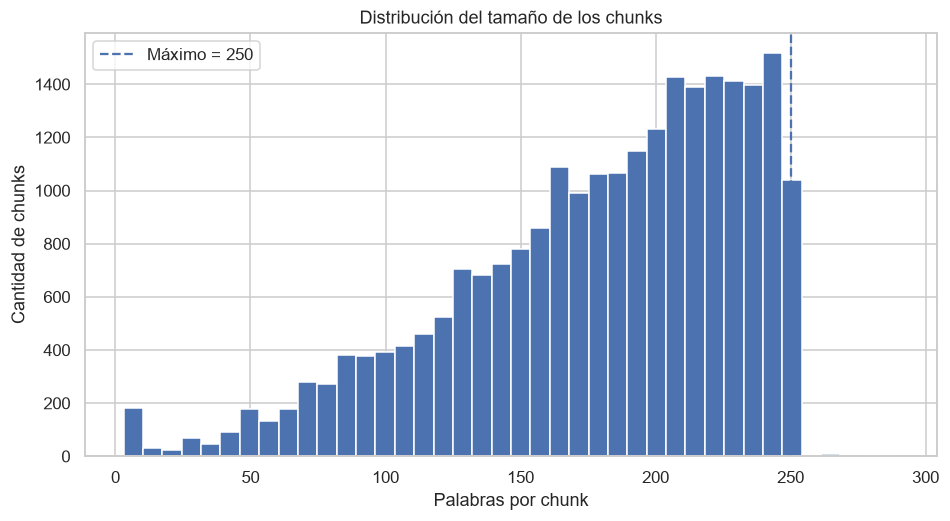

In [48]:
# ============================================================
# DISTRIBUCIÓN DE TAMAÑOS DE CHUNKS
# ============================================================

print(
    df_chunks["num_palabras"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

plt.figure(figsize=(10, 5))

plt.hist(
    df_chunks["num_palabras"],
    bins=40
)

plt.axvline(
    MAX_PALABRAS,
    linestyle="--",
    label=f"Máximo = {MAX_PALABRAS}"
)

plt.xlabel("Palabras por chunk")
plt.ylabel("Cantidad de chunks")
plt.title("Distribución del tamaño de los chunks")
plt.legend()

plt.show()

In [49]:
# ============================================================
# 3.2 BAG OF WORDS
# ============================================================

bow_vectorizer = CountVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b\w+\b"
)

X_bow = bow_vectorizer.fit_transform(
    df_chunks["texto_normalizado"]
)

print("Matriz BoW:", X_bow.shape)
print(
    "Tamaño vocabulario:",
    len(bow_vectorizer.vocabulary_)
)

Matriz BoW: (24003, 25935)
Tamaño vocabulario: 25935


In [50]:
# ============================================================
# EJEMPLO DE REPRESENTACIÓN BOW
# ============================================================

bow_features = bow_vectorizer.get_feature_names_out()

print("Primeras 30 características:")
print(bow_features[:30])

print("\nForma de la matriz:")
print(X_bow.shape)

print("\nMatriz del primer chunk:")
print(
    X_bow[0].toarray()
)

Primeras 30 características:
['aadi' 'aanmg' 'aarhus' 'aat' 'aba' 'abad' 'abajo' 'abanderan'
 'abandonado' 'abandonar' 'abandonarar' 'abandono' 'abanico' 'abarca'
 'abarcada' 'abarcado' 'abarcar' 'abarcarir' 'abarco' 'abarrot' 'abarullo'
 'abarza' 'abarzua' 'abastecer' 'abastecimiento' 'abatido' 'abatir'
 'abbott' 'abc' 'abdalá']

Forma de la matriz:
(24003, 25935)

Matriz del primer chunk:
[[0 0 0 ... 0 0 0]]


In [51]:
# ============================================================
# 3.3 TF-IDF
# ============================================================

tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b\w+\b",
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_tfidf = tfidf_vectorizer.fit_transform(
    df_chunks["texto_normalizado"]
)

print("Matriz TF-IDF:", X_tfidf.shape)

print(
    "Vocabulario:",
    len(tfidf_vectorizer.vocabulary_)
)

Matriz TF-IDF: (24003, 203730)
Vocabulario: 203730


In [52]:
# ============================================================
# CARACTERÍSTICAS TF-IDF
# ============================================================

tfidf_features = (
    tfidf_vectorizer
    .get_feature_names_out()
)

print("Primeras 50 características:")
print(tfidf_features[:50])

Primeras 50 características:
['abad' 'abajo' 'abajo suelo' 'abandonado' 'abandonado alta' 'abandonar'
 'abandonar cargo' 'abandonar definitivamente' 'abandonar demarcación'
 'abandonar domicilio' 'abandonar ecuador' 'abandonar estudio'
 'abandonar fila' 'abandonar fuente' 'abandonar hogar'
 'abandonar hospital' 'abandonar lugar' 'abandonar oroya' 'abandonar país'
 'abandonar plaza' 'abandonar residencia' 'abandonar territorio'
 'abandonar trabajo' 'abandonar voluntariamente' 'abandonar él'
 'abandonarar' 'abandono' 'abandono alta' 'abandono causa'
 'abandono instancia' 'abandono negligencia' 'abandono principio'
 'abandono procedimiento' 'abandono trabajo' 'abanico' 'abarca'
 'abarca atención' 'abarca campo' 'abarca expedición' 'abarca motivo'
 'abarca subsiguiente' 'abarcada' 'abarcada entendimiento' 'abarcado'
 'abarcado reconocimiento' 'abarcar' 'abarcar acción' 'abarcar actuación'
 'abarcar art' 'abarcar aspecto']


In [53]:
import torch
print("Torch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Capacidad:", torch.cuda.get_device_capability(0))
    print("Memoria total (GB):", round(torch.cuda.get_device_properties(0).total_memory/1e9, 2))

Torch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce RTX 4070
Capacidad: (8, 9)
Memoria total (GB): 12.88


In [54]:
%pip -q install -U sentence-transformers

import torch
from sentence_transformers import SentenceTransformer

MODELO_EMBEDDING = "intfloat/multilingual-e5-base"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

embedding_model = SentenceTransformer(MODELO_EMBEDDING, device=DEVICE)

if DEVICE == "cuda":
    embedding_model = embedding_model.half()      # fp16 → ~2x más rápido

embedding_model.max_seq_length = 256              # baja a 256 si tus chunks son cortos
print("Modelo cargado.")

Note: you may need to restart the kernel to use updated packages.
Device: cuda


Modelo cargado.


In [55]:
# ============================================================
# GENERACIÓN DE EMBEDDINGS PARA LOS CHUNKS
# ============================================================

import numpy as np
import torch

textos_embedding = [f"passage: {t}" for t in df_chunks["texto_con_contexto"]]
print("N chunks:", len(textos_embedding))

with torch.inference_mode():
    embeddings = embedding_model.encode(
        textos_embedding,
        batch_size=256,              # RTX 4070 12GB aguanta 256 sin problema
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True,
        device=DEVICE,
    )

embeddings = embeddings.astype(np.float32)
print("Forma:", embeddings.shape)



N chunks: 24003


Forma: (24003, 768)


In [56]:
# ============================================================
# 3.5 VISUALIZACIÓN
# ============================================================

!pip -q install umap-learn

import umap.umap_ as umap

# ============================================================
# REDUCCIÓN DE DIMENSIONALIDAD CON UMAP
# ============================================================

MAX_VIS = min(
    2000,
    len(embeddings)
)

rng = np.random.default_rng(42)

indices_vis = rng.choice(
    len(embeddings),
    size=MAX_VIS,
    replace=False
)

embeddings_vis = embeddings[
    indices_vis
]

df_vis = df_chunks.iloc[
    indices_vis
].copy()

reducer = umap.UMAP(
    n_components=2,
    random_state=42,
    n_neighbors=15,
    min_dist=0.1
)

embedding_2d = reducer.fit_transform(
    embeddings_vis
)

print(
    "Dimensiones después de UMAP:",
    embedding_2d.shape
)

Dimensiones después de UMAP: (2000, 2)


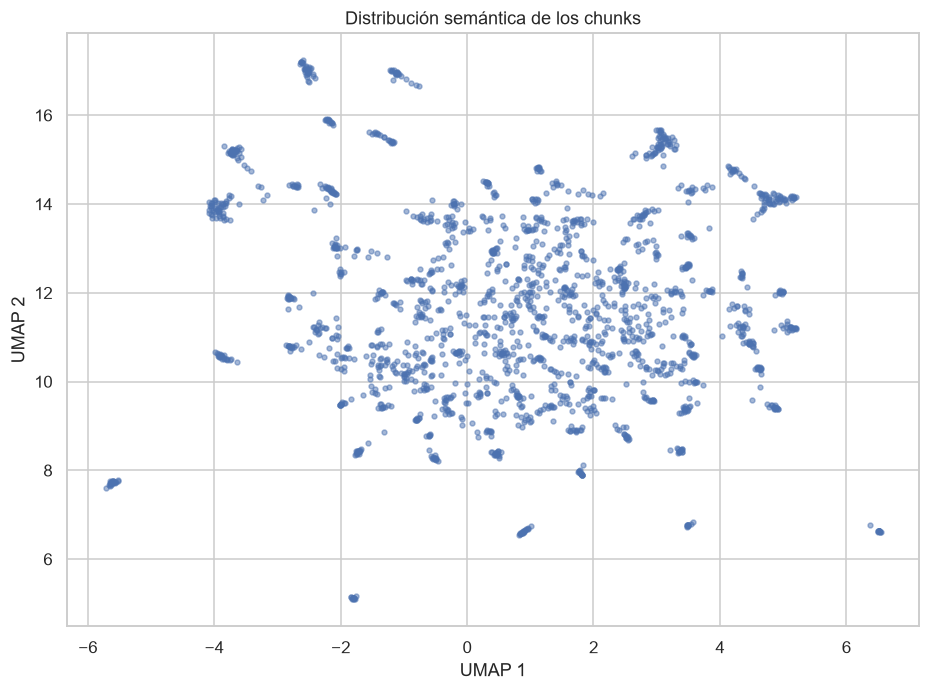

In [57]:
# ============================================================
# GRÁFICO DE LOS EMBEDDINGS
# ============================================================

plt.figure(figsize=(10, 7))

plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    s=10,
    alpha=0.5
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.title(
    "Distribución semántica de los chunks"
)

plt.show()

In [58]:
# ============================================================
# 3.7 RECUPERACIÓN CON TF-IDF
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity


def buscar_tfidf(
    consulta,
    k=5
):
    """
    Recupera los k chunks más similares
    mediante TF-IDF y similitud coseno.
    """

    # la consulta pasa por la misma normalización que los chunks (lemas, sin stopwords, art_8_1)
    consulta_vector = tfidf_vectorizer.transform([normalizar(consulta)])

    scores = cosine_similarity(
        consulta_vector,
        X_tfidf
    )[0]

    indices = np.argsort(
        scores
    )[::-1][:k]

    resultados = df_chunks.iloc[
        indices
    ].copy()

    resultados["score"] = scores[
        indices
    ]

    resultados["rank"] = range(
        1,
        len(resultados) + 1
    )

    return resultados

In [59]:
!pip -q install faiss-cpu

import faiss

# ============================================================
# CREAR ÍNDICE FAISS
# ============================================================

dimension = embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(
    dimension
)

faiss_index.add(
    embeddings
)

print(
    "Vectores indexados:",
    faiss_index.ntotal
)

print(
    "Dimensión:",
    dimension
)

Vectores indexados: 24003
Dimensión: 768


In [60]:
# ============================================================
# BÚSQUEDA SEMÁNTICA
# ============================================================

def buscar_denso(
    consulta,
    k=5
):
    """
    Recupera los k chunks más similares
    mediante embeddings y FAISS.
    """

    query_embedding = embedding_model.encode(
        [f"query: {consulta}"],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype(np.float32)

    scores, indices = faiss_index.search(
        query_embedding,
        k
    )

    indices = indices[0]
    scores = scores[0]

    resultados = df_chunks.iloc[
        indices
    ].copy()

    resultados["score"] = scores

    resultados["rank"] = range(
        1,
        len(resultados) + 1
    )

    return resultados

In [61]:
# ============================================================
# 3.9 COMPARACIÓN DE RECUPERACIÓN
# ============================================================

CONSULTA = (
    "libertad de expresión "
    "y periodistas"
)


print("=" * 80)
print("TF-IDF")
print("=" * 80)

resultados_tfidf = buscar_tfidf(
    CONSULTA,
    k=5
)

display(
    resultados_tfidf[
        [
            "rank",
            "titulo",
            "estado",
            "anio",
            "seccion",
            "parr_ini",
            "parr_fin",
            "score"
        ]
    ]
)


print("\n")
print("=" * 80)
print("EMBEDDINGS")
print("=" * 80)

resultados_denso = buscar_denso(
    CONSULTA,
    k=5
)

display(
    resultados_denso[
        [
            "rank",
            "titulo",
            "estado",
            "anio",
            "seccion",
            "parr_ini",
            "parr_fin",
            "score"
        ]
    ]
)

TF-IDF


,rank,titulo,estado,anio,seccion,parr_ini,parr_fin,score
15891,1,caso palacio urrutia y otros vs. ecuador,ecuador,2021,VII. FONDO,147.0,147.0,0.301973
17186,2,caso moya chacón y otro vs. costa rica,costa rica,2022,"VII. FONDO DERECHO A LA LIBERTAD DE PENSAMIENTO Y EXPRESIÓN, GARANTÍAS JUDICIALES Y PR...",68.0,68.0,0.237998
17878,3,caso leguizamón zaván y otros vs. paraguay,paraguay,2022,"VII-1. DERECHOS A LA VIDA Y A LA LIBERTAD DE PENSAMIENTO Y DE EXPRESIÓN, EN RELACIÓN C...",47.0,48.0,0.227844
15811,4,caso palacio urrutia y otros vs. ecuador,ecuador,2021,VI. HECHOS,48.0,48.0,0.189729
17134,5,caso moya chacón y otro vs. costa rica,costa rica,2022,I. INTRODUCCIÓN DE LA CAUSA Y OBJETO DE LA CONTROVERSIA,1.0,1.0,0.186418




EMBEDDINGS


,rank,titulo,estado,anio,seccion,parr_ini,parr_fin,score
17187,1,caso moya chacón y otro vs. costa rica,costa rica,2022,"VII. FONDO DERECHO A LA LIBERTAD DE PENSAMIENTO Y EXPRESIÓN, GARANTÍAS JUDICIALES Y PR...",69.0,70.0,0.867998
15849,2,caso palacio urrutia y otros vs. ecuador,ecuador,2021,VII. FONDO,94.0,94.0,0.866093
17883,3,caso leguizamón zaván y otros vs. paraguay,paraguay,2022,"VII-1. DERECHOS A LA VIDA Y A LA LIBERTAD DE PENSAMIENTO Y DE EXPRESIÓN, EN RELACIÓN C...",54.0,55.0,0.865544
17183,4,caso moya chacón y otro vs. costa rica,costa rica,2022,"VII. FONDO DERECHO A LA LIBERTAD DE PENSAMIENTO Y EXPRESIÓN, GARANTÍAS JUDICIALES Y PR...",65.0,65.0,0.864619
13993,5,caso bedoya lima y otra vs. colombia,colombia,2021,VIII. FONDO,149.0,149.0,0.863385


In [62]:
# ============================================================
# PRUEBAS DE RECUPERACIÓN
# ============================================================

CONSULTAS = [
    "libertad de expresión y periodistas",
    "desaparición forzada y obligación de investigar",
    "propiedad comunal de pueblos indígenas",
    "reparaciones ordenadas por la Corte Interamericana"
]


for consulta in CONSULTAS:

    print("\n")
    print("=" * 100)
    print("CONSULTA:", consulta)
    print("=" * 100)

    resultados = buscar_denso(
        consulta,
        k=3
    )

    for _, fila in resultados.iterrows():

        print(
            f"\n[{fila['rank']}] "
            f"{fila['titulo']}"
        )

        print(
            f"Sección: {fila['seccion']}"
        )

        print(
            f"Párrafos: "
            f"{fila['parr_ini']}–{fila['parr_fin']}"
        )

        print(
            fila["texto"][:700],
            "..."
        )



CONSULTA: libertad de expresión y periodistas

[1] caso moya chacón y otro vs. costa rica
Sección: VII. FONDO DERECHO A LA LIBERTAD DE PENSAMIENTO Y EXPRESIÓN, GARANTÍAS JUDICIALES Y PRINCIPIO DE LEGALIDAD Y DE RETROACTIVIDAD EN RELACIÓN CON LA OBLIGACIÓN
Párrafos: 69.0–70.0
Además, dada la importancia de la libertad de expresión en una sociedad democrática y la elevada responsabilidad que ello entraña para quienes ejercen profesionalmente labores de comunicación social, el Estado no sólo debe minimizar las restricciones a la circulación de la información sino también equilibrar, en la mayor medida de lo posible, la participación de las distintas informaciones en el debate público, impulsando el pluralismo informativo. Por último, la Corte ha indicado que es fundamental que los periodistas que laboran en los medios de comunicación gocen de la protección y de la independencia necesarias para realizar sus funciones a cabalidad, ya que son ellos quienes mantienen i ...

[2] caso palacio


[1] caso flores bedregal y otras vs. bolivia
Sección: VII. FONDO
Párrafos: 118.0–118.0
Asimismo, la Corte ha señalado que los órganos estatales encargados de la investigación relacionada con la desaparición forzada de personas; cuyos objetivos son la determinación de su paradero y el esclarecimiento de lo sucedido, la identificación de los responsables y su posible sanción; deben llevar a cabo su tarea de manera diligente y exhaustiva. En casos de desapariciones forzadas, la obligación de investigar se ve reforzada por las obligaciones establecidas en las normas respectivas de la Convención Interamericana sobre Desaparición Forzada, entre las que cabe mencionar, por ser relevante en este caso, la prescrita en el artículo I, inciso b), referida al deber de sancionar el delito d ...

[2] caso cuéllar sandoval y otros vs. el salvador
Sección: VII-2. DERECHOS A LAS GARANTÍAS JUDICIALES Y A LA PROTECCIÓN JUDICIAL
Párrafos: 88.0–88.0
Además, esta Corte ha considerado que, una vez ocurre una


[1] caso asociación civil memoria activa vs. argentina
Sección: IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN
Párrafos: 13.0–16.0
A continuación, la Corte Interamericana examinará las cuestiones planteadas en el siguiente orden: (A) Solicitud de aclaración respecto la determinación del plazo de cumplimiento de pago de las reparaciones fijadas por la Corte; (B) Solicitud de interpretación con relación al uso de las palabras "informe" y "dictamen"; (C) Solicitud de interpretación con respecto a la no mención al Decreto 213/20; (D) Solicitud de interpretación sobre la Agencia de Inteligencia como responsable del encubrimiento, y (E) Solicitudes de interpretación con relación a las reparaciones. A. Solicitud de aclaración respecto la determinación del plazo de cumplimiento de pago de las reparaciones fijadas por la Corte A ...

[2] caso yangali iparraguirre vs. perú
Sección: IX. REPARACIONES
Párrafos: 194.0–196.0
Con fundamento en lo dispuesto en el artículo 63.1 de 

In [63]:
# ============================================================
# 3.11 EVALUACIÓN INICIAL
# ============================================================

def recall_at_k(
    retrieved,
    relevant,
    k
):
    """
    Indica si al menos un elemento relevante
    aparece dentro de los primeros k resultados.
    """

    return int(
        any(
            item in relevant
            for item in retrieved[:k]
        )
    )


def reciprocal_rank(
    retrieved,
    relevant,
    k=10
):
    """
    Reciprocal Rank.
    """

    for rank, item in enumerate(
        retrieved[:k],
        start=1
    ):

        if item in relevant:
            return 1 / rank

    return 0.0

In [64]:
# ============================================================
# SMOKE TEST DE RECUPERACIÓN
# ============================================================

candidatos_eval = df_chunks[
    df_chunks["num_palabras"] >= 40
].head(5)

resultados_eval = []


for _, fila in candidatos_eval.iterrows():

    palabras = fila["texto"].split()

    consulta = " ".join(
        palabras[:25]
    )

    indice_correcto = fila.name

    resultados = buscar_denso(
        consulta,
        k=10
    )

    recuperados = (
        resultados.index.tolist()
    )

    relevante = {
        indice_correcto
    }

    resultados_eval.append({

        "consulta": consulta[:100],

        "Recall@1":
            recall_at_k(
                recuperados,
                relevante,
                1
            ),

        "Recall@5":
            recall_at_k(
                recuperados,
                relevante,
                5
            ),

        "Recall@10":
            recall_at_k(
                recuperados,
                relevante,
                10
            ),

        "MRR@10":
            reciprocal_rank(
                recuperados,
                relevante,
                10
            )
    })


df_eval = pd.DataFrame(
    resultados_eval
)

display(df_eval)

,consulta,Recall@1,Recall@5,Recall@10,MRR@10
0,"El 27 de julio de 2022, la Corte Interamericana emitió la Sentencia en el presente cas...",0,1,1,0.250000
1,"El 28 de abril de 2023, los intervinientes comunes de la Corporación Reiniciar present...",1,1,1,1.000000
2,"El 30 de abril de 2023, la Comisión Colombiana de Juristas, remitió una nota a la Cort...",1,1,1,1.000000
3,El 9 de junio de 2023 la Comisión presentó sus observaciones escritas respecto de las ...,0,1,1,0.500000
4,El artículo 67 de la Convención establece que: [e]l fallo de la Corte será definitivo ...,0,0,1,0.142857


In [65]:
# ============================================================
# RESUMEN DE EVALUACIÓN
# ============================================================

print(
    "Promedio de métricas:"
)

display(
    df_eval[
        [
            "Recall@1",
            "Recall@5",
            "Recall@10",
            "MRR@10"
        ]
    ].mean()
)

Promedio de métricas:


Recall@1     0.400000
Recall@5     0.800000
Recall@10    1.000000
MRR@10       0.578571
dtype: float64

In [66]:
# ============================================================
# 3.12 GUARDAR CHUNKS
# ============================================================

OUT_DIR = PROC_DIR / "caracteristicas"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHUNKS_PATH = OUT_DIR / "chunks.parquet"

df_chunks.to_parquet(CHUNKS_PATH, index=False)

print(
    "Chunks guardados en:",
    CHUNKS_PATH
)

Chunks guardados en: C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas\chunks.parquet


In [67]:
# ============================================================
# GUARDAR EMBEDDINGS
# ============================================================

EMBEDDINGS_PATH = (
    OUT_DIR / "embeddings.npy"
)

np.save(
    EMBEDDINGS_PATH,
    embeddings
)

print(
    "Embeddings guardados en:",
    EMBEDDINGS_PATH
)

Embeddings guardados en: C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas\embeddings.npy


In [68]:
# ============================================================
# GUARDAR ÍNDICE FAISS
# ============================================================

FAISS_PATH = (
    OUT_DIR / "indice.faiss"
)

faiss.write_index(
    faiss_index,
    str(FAISS_PATH)
)

print(
    "Índice FAISS guardado en:",
    FAISS_PATH
)

Índice FAISS guardado en: C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas\indice.faiss


In [69]:
# ============================================================
# GUARDAR TF-IDF
# ============================================================

import joblib

TFIDF_PATH = (
    OUT_DIR / "tfidf_vectorizer.joblib"
)

joblib.dump(
    tfidf_vectorizer,
    TFIDF_PATH
)

print(
    "Vectorizador TF-IDF guardado en:",
    TFIDF_PATH
)

Vectorizador TF-IDF guardado en: C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas\tfidf_vectorizer.joblib


In [70]:
print(Path(OUT_DIR / "chunks.parquet").stat().st_size / 1e6, "MB chunks")
print(Path(OUT_DIR / "embeddings.npy").stat().st_size / 1e6, "MB embeddings")
print(Path(OUT_DIR / "indice.faiss").stat().st_size / 1e6, "MB faiss")
print(Path(OUT_DIR / "tfidf_vectorizer.joblib").stat().st_size / 1e6, "MB tfidf")

33.292622 MB chunks
73.737344 MB embeddings
73.737261 MB faiss
6.471367 MB tfidf
